# Dự đoán giá ô tô bằng Random Forest

**Bài toán:** hồi quy có giám sát, dự đoán **giá rao bán (triệu đồng)** của ô tô cũ và mới trên Chợ Tốt từ các đặc trưng của xe.

**Dữ liệu:** `clean_data_oto.csv`, kết quả của `preprocess_data.ipynb` (13.937 tin, đã loại giá sai, điền thiếu, gộp nhãn hiếm theo cấp).

**Mô hình chính: Random Forest**, làm hai bản và kiểm chứng chéo:

| Bản | Vai trò |
|---|---|
| **(A) Thư viện** `sklearn.ensemble.RandomForestRegressor` | chuẩn đối chiếu, chạy nhanh |
| **(B) Tự cài đặt bằng NumPy** (cây CART tìm ngưỡng bằng histogram, bootstrap, chọn ngẫu nhiên đặc trưng, OOB, độ quan trọng đặc trưng) | đáp ứng yêu cầu viết mô hình từ đầu đến cuối; so với bản (A) trên cùng dữ liệu, cùng tham số |

Cây quyết định (Decision Tree) xuất hiện như **thành phần** của rừng và được kiểm chứng riêng ở mục 5.2.

**Mô hình so sánh: Ridge Regression (chỉ dùng thư viện).** Ridge là mô hình tuyến tính, chỉ dùng làm **mốc** để trả lời một câu hỏi: quan hệ phi tuyến và tương tác giữa các đặc trưng mà Random Forest học được đóng góp bao nhiêu vào độ chính xác? Notebook không tự cài đặt Ridge và không phân tích sâu mô hình này.

**Quy trình**

1. Dữ liệu, đặc trưng, chia train/test (80/20, phân tầng theo phân khúc giá)
2. Thước đo đánh giá và mô hình mốc (baseline)
3. Chuẩn bị đặc trưng cho Random Forest: one-hot hay mã số thứ tự?
4. Random Forest: bản thư viện
5. Random Forest: bản tự cài đặt
6. Ridge (thư viện): mô hình so sánh
7. Kết quả trên tập test
8. Diễn giải Random Forest: đặc trưng nào quyết định giá
9. Thí nghiệm: log giá và các kỹ thuật xử lý mất cân bằng
10. Hạn chế: tin đăng lại và chia theo nhóm
11. Xuất mô hình
12. Kết luận

**Nguyên tắc chống rò rỉ dữ liệu:** mọi lựa chọn (cách mã hóa, tham số, cách biến đổi biến mục tiêu, kỹ thuật cân bằng) đều quyết định bằng **cross-validation hoặc OOB trên tập train**. Tập test chỉ dùng ở mục 7 để báo cáo kết quả cuối (mục 8 và 10 dùng lại dự đoán trên test để diễn giải, không để chọn gì).

Các biểu đồ được lưu vào `figures/m*.png` (200 dpi) để đưa vào báo cáo.

In [1]:
import time, json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, StratifiedGroupKFold,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9aa0a6"
LIGHT_BLUE, LIGHT_ORANGE = "#8fb8ee", "#f4a98a"
RANDOM_STATE = 42

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save(fig, name):
    # Lưu biểu đồ để đưa vào báo cáo
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## 1. Dữ liệu, đặc trưng và chia train/test

### 1.1 Biến mục tiêu
Mô hình học **`ln(giá)`** thay vì giá gốc. Giá lệch phải rất mạnh (đa số xe 200-800 triệu, một ít xe vài tỷ); học trên giá gốc thì sai số của vài xe đắt lấn át tất cả. Log biến sai số tuyệt đối thành sai số **tương đối**: đoán lệch 10% ở xe 200 triệu và ở xe 2 tỷ được phạt như nhau, khớp với thước đo chính MAPE. Lựa chọn này được **kiểm chứng bằng số liệu** ở mục 9.

Dự đoán xong dùng `exp()` để đổi về triệu đồng, và **mọi metric đều tính trên giá thật**.

### 1.2 Đặc trưng
Chỉ dùng thông tin người mua thấy trong tin đăng.

| Nhóm | Random Forest (mô hình chính) | Ridge (so sánh) |
|---|---|---|
| Phân loại | hãng (`carbrand_grp`), dòng xe (`carmodel_grp`), xuất xứ, tình trạng, hộp số, nhiên liệu, kiểu dáng; one-hot (cách mã hóa được kiểm chứng ở mục 3) | như RF, one-hot |
| Tuổi xe | `age` | `age`, `age²` |
| Số km | `mileage_km`, `km_per_year` giữ nguyên | `log(1+km)`, `log(1+km/năm)` |
| Khác | `carseats`, `mileage_missing` | như RF, chuẩn hóa |

- **Random Forest không cần biến đổi đặc trưng số:** cây chỉ so sánh ngưỡng (`age ≤ 5?`), nên mọi biến đổi đơn điệu (`age²`, `log`) đều cho cùng phép chia. Thêm `age²` chỉ làm độ quan trọng đặc trưng bị chia đôi. Cây cũng không phụ thuộc thang đo nên **không chuẩn hóa**.
- **Ridge cần `age²`, `log` và chuẩn hóa** vì chỉ cộng các hiệu ứng tuyến tính (xe mất giá nhanh những năm đầu rồi chậm lại), và khoản phạt L2 cần các đặc trưng cùng thang đo.
- **Không dùng:** `price_tr`, `price_log` (đáp án), `mfdate` (trùng `age`), `carbrand`/`carmodel` gốc (đã thay bằng bản gộp nhãn hiếm), `province` (`preprocess_data.ipynb` mục 7.4 cho thấy vị trí gần như không giúp dự đoán).

### 1.3 Chia train/test
80/20, **phân tầng theo phân khúc giá** để tập test có đủ xe ở mọi phân khúc, đặc biệt xe trên 2 tỷ (chỉ khoảng 3% dữ liệu). Bộ mã hóa **fit trên train** rồi áp lên test. Không tách tập validation riêng: tham số được chọn bằng cross-validation (hoặc OOB) trên train.

In [2]:
df = pd.read_csv("clean_data_oto.csv")
df["price_log"] = np.log(df["price_tr"])                 # biến mục tiêu: ln(giá triệu đồng)
# Tính lại km/năm đúng công thức trong model/price_model.py, để dự đoán khi nạp lại mô hình khớp tuyệt đối
# (giá trị đọc từ CSV có thể lệch ở chữ số thập phân cuối do làm tròn khi ghi file)
df["km_per_year"] = df["mileage_km"] / df["age"].clip(lower=1)

# Đặc trưng biến đổi, chỉ dùng cho Ridge
df["age_sq"] = df["age"] ** 2
df["log_km"] = np.log1p(df["mileage_km"])
df["log_km_per_year"] = np.log1p(df["km_per_year"])

SEG_BINS = [0, 200, 500, 1000, 2000, np.inf]
SEG_LABELS = ["< 200 triệu", "200-500", "500-1.000", "1-2 tỷ", "> 2 tỷ"]
df["segment"] = pd.cut(df["price_tr"], bins=SEG_BINS, labels=SEG_LABELS, right=False).astype(str)

# Khóa nhóm: các tin giống hệt mọi đặc trưng, kể cả số km, nhiều khả năng là cùng một xe đăng lại (dùng ở mục 10)
FEAT_KEY = ["carbrand", "carmodel", "carorigin", "condition_ad", "gearbox", "fuel", "cartype", "carseats", "mfdate", "mileage_km"]
df["group_key"] = df[FEAT_KEY].astype(str).agg("|".join, axis=1)

CAT = ["carbrand_grp", "carmodel_grp", "carorigin", "condition_ad", "gearbox", "fuel", "cartype"]
NUM_TREE = ["age", "mileage_km", "carseats", "km_per_year", "mileage_missing"]
NUM_LIN = ["age", "age_sq", "log_km", "carseats", "log_km_per_year", "mileage_missing"]

idx_tr, idx_te = train_test_split(df.index, test_size=0.2, stratify=df["segment"], random_state=RANDOM_STATE)
tr, te = df.loc[idx_tr], df.loc[idx_te]


def make_prep(kind):
    # Bộ tiền xử lý: one-hot cho biến phân loại; giữ nguyên biến số (cây) hoặc chuẩn hóa (Ridge)
    num = ("num", "passthrough", NUM_TREE) if kind == "tree" else ("num", StandardScaler(), NUM_LIN)
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT), num])


prep_tree, prep_lin = make_prep("tree"), make_prep("lin")
XT_tr, XT_te = prep_tree.fit_transform(tr), prep_tree.transform(te)    # fit chỉ trên train
XL_tr, XL_te = prep_lin.fit_transform(tr), prep_lin.transform(te)
names_tree = [n.split("__", 1)[1] for n in prep_tree.get_feature_names_out()]

y_tr, y_te = tr["price_log"].values, te["price_log"].values            # thang log: để huấn luyện
p_tr, p_te = tr["price_tr"].values, te["price_tr"].values              # triệu đồng: để đánh giá
seg_tr, seg_te = tr["segment"].values, te["segment"].values

print(f"Dữ liệu: {len(df)} tin | train {len(tr)} | test {len(te)}")
print(f"Số cột sau mã hóa: Random Forest {XT_tr.shape[1]} | Ridge {XL_tr.shape[1]}")

Dữ liệu: 13937 tin | train 11149 | test 2788
Số cột sau mã hóa: Random Forest 277 | Ridge 278


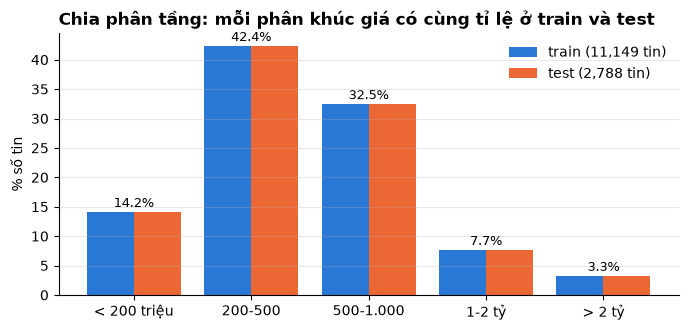

In [3]:
seg_share = pd.DataFrame({"train": pd.Series(seg_tr).value_counts(normalize=True),
                          "test": pd.Series(seg_te).value_counts(normalize=True)}).reindex(SEG_LABELS) * 100

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(SEG_LABELS))
ax.bar(x - 0.2, seg_share["train"], 0.4, color=BLUE, label=f"train ({len(tr):,} tin)")
ax.bar(x + 0.2, seg_share["test"], 0.4, color=ORANGE, label=f"test ({len(te):,} tin)")
for i, v in enumerate(seg_share["train"]):
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(SEG_LABELS)
ax.set_ylabel("% số tin"); ax.set_title("Chia phân tầng: mỗi phân khúc giá có cùng tỉ lệ ở train và test", loc="left")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
save(fig, "m01_chia_train_test"); plt.show()

## 2. Thước đo đánh giá

Dùng nhiều thước đo vì mỗi cái trả lời một câu hỏi khác nhau. Tất cả tính trên **giá thật (triệu đồng)**:

| Thước đo | Ý nghĩa | Vì sao dùng |
|---|---|---|
| **MAPE** | sai số phần trăm trung bình | **Thước đo chính.** Lệch 100 triệu là nhỏ với xe 3 tỷ nhưng rất lớn với xe 150 triệu |
| **MedAPE** | trung vị sai số phần trăm | Sai số "điển hình", không bị vài tin sai nặng kéo lệch |
| **MAE** | sai số tuyệt đối trung bình (triệu) | Dễ hiểu: "trung bình đoán lệch bao nhiêu tiền" |
| **RMSE** | căn trung bình bình phương sai số (triệu) | Phạt nặng các lỗi lớn (thường ở xe sang) |
| **R² (log)** | tỉ lệ biến thiên của log giá được giải thích | Đo trên đúng thang mô hình học; R² trên giá gốc bị vài xe đắt chi phối |
| **±10% / ±20%** | tỉ lệ tin được đoán lệch không quá 10% / 20% | Diễn giải cho người dùng: "bao nhiêu % xe được định giá sát" |

Ngoài ra luôn báo **MAPE theo từng phân khúc giá**: một con số trung bình sẽ che mất việc mô hình kém ở xe rất rẻ hoặc rất đắt.

**Mô hình mốc (baseline):** luôn đoán giá trung vị của tập train. Mô hình nào cũng phải tốt hơn hẳn mức này mới có ý nghĩa.

In [4]:
def regression_metrics(p_true, p_pred):
    p_pred = np.clip(p_pred, 1, None)
    err = p_pred - p_true
    ape = np.abs(err) / p_true
    lt, lp = np.log(p_true), np.log(p_pred)
    return {
        "MAPE": ape.mean(),
        "MedAPE": np.median(ape),
        "MAE (triệu)": np.mean(np.abs(err)),
        "RMSE (triệu)": np.sqrt(np.mean(err ** 2)),
        "R2 (log)": 1 - np.sum((lt - lp) ** 2) / np.sum((lt - lt.mean()) ** 2),
        "±10%": np.mean(ape <= 0.10),
        "±20%": np.mean(ape <= 0.20),
    }


def segment_mape(p_true, p_pred, seg):
    ape = np.abs(np.clip(p_pred, 1, None) - p_true) / p_true
    return {f"MAPE {s}": ape[seg == s].mean() for s in SEG_LABELS}


results, preds = {}, {}


def record(name, log_pred, fit_seconds):
    # Lưu metric trên tập test (log_pred là dự đoán trên thang log)
    p_pred = np.exp(log_pred)
    preds[name] = p_pred
    results[name] = {**regression_metrics(p_te, p_pred), **segment_mape(p_te, p_pred, seg_te),
                     "Thời gian fit (s)": fit_seconds}
    return pd.Series(results[name]).round(3).to_frame(name).T


t0 = time.time()
dummy = DummyRegressor(strategy="median").fit(XL_tr, y_tr)
record("Baseline (trung vị)", dummy.predict(XL_te), time.time() - t0)

,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ,Thời gian fit (s)
Baseline (trung vị),0.835,0.4,336.968,723.755,-0.003,0.137,0.256,3.498,0.385,0.307,0.641,0.854,0.001


## 3. Chuẩn bị đặc trưng cho Random Forest: one-hot hay mã số thứ tự?

Biến phân loại phải đổi thành số trước khi đưa vào cây. Có hai cách:

| Cách | Làm gì | Ưu | Nhược |
|---|---|---|---|
| **One-hot** | mỗi nhãn thành một cột 0/1 (dòng xe có hơn 200 nhãn nên sinh hơn 200 cột) | không tạo thứ tự giả; mỗi phép chia tách đúng một nhãn khỏi phần còn lại | nhiều cột; độ quan trọng của một đặc trưng bị chia nhỏ ra nhiều cột; `max_features` lấy ngẫu nhiên phần lớn là các cột one-hot |
| **Mã số thứ tự** (`OrdinalEncoder`) | mỗi nhãn thành một số nguyên 0, 1, 2... trong **một** cột | chỉ 12 cột; cây có thể gom nhiều nhãn vào một nhánh qua vài lần chia | thứ tự các nhãn là tùy ý (theo bảng chữ cái), cây phải chia nhiều lần mới tách được một nhãn ở giữa |

Với Ridge chỉ có one-hot là đúng (thứ tự giả làm sai hệ số), nhưng **cây không bị ảnh hưởng nặng bởi thứ tự giả**, nên đây là câu hỏi thực nghiệm. So sánh bằng **5-fold CV phân tầng chỉ trên tập train**, bộ mã hóa fit trong phần train của từng fold. Tham số rừng cố định ở mức hợp lý (150 cây, `max_depth = 30`); riêng `max_features` thử vài mức với mã số thứ tự vì số cột khác hẳn (12 so với khoảng 270 cột).

In [5]:
def prep_ordinal():
    # Mã số thứ tự: mỗi biến phân loại thành một cột số nguyên; nhãn lạ ở dữ liệu mới -> -1
    return ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT),
                              ("num", "passthrough", NUM_TREE)])


def cv_rf(make_prep_fn, params, splitter=None, groups=None):
    # Dự đoán out-of-fold (triệu đồng) trên tập train bằng RandomForestRegressor; bộ mã hóa fit trong từng fold
    splitter = splitter or StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    oof = np.zeros(len(tr))
    for a, b in splitter.split(tr, seg_tr, groups):
        prep = make_prep_fn()
        m = RandomForestRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1)
        m.fit(prep.fit_transform(tr.iloc[a]), y_tr[a])
        oof[b] = np.exp(m.predict(prep.transform(tr.iloc[b])))
    return {"MAPE": regression_metrics(p_tr, oof)["MAPE"], **segment_mape(p_tr, oof, seg_tr)}


PROBE = {"n_estimators": 150, "max_depth": 30, "min_samples_leaf": 1}
enc_variants = {
    "One-hot, max_features = 0.33": (lambda: make_prep("tree"), 0.33),
    "Mã số thứ tự, max_features = 0.33": (prep_ordinal, 0.33),
    "Mã số thứ tự, max_features = 0.6": (prep_ordinal, 0.6),
    "Mã số thứ tự, max_features = 1.0": (prep_ordinal, 1.0),
}
t0 = time.time()
enc_rows = {}
for name, (fn, mf) in enc_variants.items():
    enc_rows[name] = {"số cột": fn().fit_transform(tr).shape[1], **cv_rf(fn, {**PROBE, "max_features": mf})}
    print(f"{name:36s} MAPE (CV) = {enc_rows[name]['MAPE']:.4f}  ({time.time() - t0:.0f}s)")
enc_res = pd.DataFrame(enc_rows).T
enc_res.round(4)

One-hot, max_features = 0.33         MAPE (CV) = 0.1637  (17s)


Mã số thứ tự, max_features = 0.33    MAPE (CV) = 0.1835  (22s)


Mã số thứ tự, max_features = 0.6     MAPE (CV) = 0.1666  (31s)


Mã số thứ tự, max_features = 1.0     MAPE (CV) = 0.1688  (42s)


,số cột,MAPE,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ
"One-hot, max_features = 0.33",277.0,0.1637,0.3653,0.1284,0.1083,0.1672,0.2890
"Mã số thứ tự, max_features = 0.33",12.0,0.1835,0.4052,0.1434,0.1172,0.1881,0.3901
"Mã số thứ tự, max_features = 0.6",12.0,0.1666,0.3780,0.1306,0.1052,0.1775,0.3011
"Mã số thứ tự, max_features = 1.0",12.0,0.1688,0.3833,0.1327,0.1082,0.1766,0.2905


**Kết luận về cách mã hóa: giữ one-hot.**
- One-hot cho MAPE (CV) **16,4%**, mã số thứ tự từ 16,7% đến 18,4% dù đã thử nhiều mức `max_features`. Chênh lệch lớn nhất ở hai đầu thang giá: xe dưới 200 triệu (36,5% so với 37,8-40,5%) và xe trên 2 tỷ (28,9% so với 29-39%).
- Lý do: với one-hot, **một** phép chia tách thẳng một dòng xe (ví dụ Mercedes G Class) khỏi phần còn lại. Với mã số thứ tự, các nhãn xếp theo bảng chữ cái nên dòng xe sang và xe rẻ nằm xen kẽ nhau; cây phải chia nhiều lần mới cô lập được một dòng xe, và dòng xe hiếm thì không đủ mẫu để chia tới đó.
- Mã số thứ tự với `max_features = 0.33` kém nhất vì mỗi nút chỉ xét 4 trên 12 đặc trưng, nhiều nút không được xét tuổi xe.
- One-hot cũng hợp với **bản tự cài đặt**: mỗi cột 0/1 nằm gọn trong 2 bin, còn mã số của hơn 200 dòng xe sẽ bị dồn vào 32 bin và mất thông tin.

## 4. Random Forest: bản thư viện

### 4.1 Ý tưởng

**Thành phần: cây hồi quy (CART).** Cây chia dữ liệu bằng các câu hỏi có/không, ví dụ *"tuổi xe ≤ 5?"*, *"dòng xe là Toyota Vios?"*. Tại mỗi nút, thuật toán thử mọi đặc trưng và mọi ngưỡng, chọn phép chia làm **giảm tổng bình phương sai số (SSE)** nhiều nhất. Với nút có $n$ mẫu, tổng nhãn $S$, chia thành trái ($n_L$, $S_L$) và phải ($n_R$, $S_R$):

$$\text{gain} = \frac{S_L^2}{n_L} + \frac{S_R^2}{n_R} - \frac{S^2}{n}$$

Lặp lại cho đến khi đạt độ sâu tối đa hoặc nút quá ít mẫu. Giá trị dự đoán ở mỗi lá là **trung bình log giá** của các xe trong lá.

**Vấn đề của một cây:** cây sâu học thuộc dữ liệu train (độ chệch thấp) nhưng **phương sai cao**: đổi vài mẫu là cấu trúc cây thay đổi hẳn.

**Random Forest giải quyết bằng cách lấy trung bình nhiều cây khác nhau:**
1. **Bootstrap:** mỗi cây học trên một mẫu lấy ngẫu nhiên **có hoàn lại** từ train (cùng kích thước, khoảng 63% mẫu khác nhau).
2. **Chọn ngẫu nhiên đặc trưng:** mỗi lần chia nút chỉ xét một tỉ lệ `max_features` đặc trưng ngẫu nhiên, để các cây ít giống nhau.
3. **Lấy trung bình** dự đoán của tất cả các cây.

Trung bình của nhiều cây ít tương quan có phương sai nhỏ hơn hẳn một cây, trong khi độ chệch gần như không đổi.

**Out-of-bag (OOB):** khoảng 37% mẫu không được chọn vào bootstrap của mỗi cây. Dự đoán các mẫu này bằng những cây "chưa thấy" chúng cho ra một **ước lượng sai số khách quan mà không cần tập validation riêng**.

| Siêu tham số | Tác dụng |
|---|---|
| `n_estimators` | số cây; nhiều hơn thì ổn định hơn, đến một mức thì bão hòa |
| `max_depth` | độ sâu tối đa của cây |
| `min_samples_leaf` | số mẫu tối thiểu ở mỗi lá; lớn hơn thì cây "mượt" hơn |
| `max_features` | tỉ lệ đặc trưng xét ở mỗi lần chia; nhỏ hơn thì các cây đa dạng hơn |

### 4.2 Tinh chỉnh `sklearn.ensemble.RandomForestRegressor`
Tinh chỉnh bằng **Randomized Search + 3-fold CV phân tầng theo phân khúc giá** trên train: thử ngẫu nhiên 12 cấu hình thay vì toàn bộ lưới, rẻ hơn mà thường tìm được cấu hình gần tốt nhất. Thước đo là RMSE trên log giá, tương đương sai số tương đối nên nhất quán với MAPE.

In [6]:
param_dist = {
    "n_estimators": [300],
    "max_depth": [20, 30, None],
    "min_samples_leaf": [1, 2, 3, 5],
    "max_features": [0.33, 0.5, 0.8],
}
folds3 = list(StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE).split(XT_tr, seg_tr))  # phân tầng theo phân khúc
t0 = time.time()
rs_rf = RandomizedSearchCV(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), param_dist, n_iter=12,
                           cv=folds3, scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE, n_jobs=1)
rs_rf.fit(XT_tr, y_tr)
print(f"Tìm kiếm mất {time.time() - t0:.0f}s | tốt nhất: {rs_rf.best_params_} | CV RMSE (log) = {-rs_rf.best_score_:.4f}")

cv_rf_tbl = pd.DataFrame(rs_rf.cv_results_)
cv_rf_tbl = cv_rf_tbl[[c for c in cv_rf_tbl if c.startswith("param_")] + ["mean_test_score"]]
cv_rf_tbl.columns = [c.replace("param_", "") for c in cv_rf_tbl.columns[:-1]] + ["CV RMSE (log)"]
cv_rf_tbl["CV RMSE (log)"] *= -1
cv_rf_tbl.sort_values("CV RMSE (log)").head(6).round(4)

Tìm kiếm mất 277s | tốt nhất: {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 30} | CV RMSE (log) = 0.2692


,n_estimators,min_samples_leaf,max_features,max_depth,CV RMSE (log)
4,300,1,0.50,30,0.2692
7,300,1,0.33,30,0.2701
6,300,2,0.80,30,0.2763
9,300,2,0.50,30,0.2766
1,300,2,0.33,30,0.2793
11,300,3,0.80,None,0.2814


In [7]:
t0 = time.time()
rf_lib = RandomForestRegressor(**rs_rf.best_params_, random_state=RANDOM_STATE, n_jobs=-1, oob_score=True).fit(XT_tr, y_tr)
t_rf_lib = time.time() - t0
print(f"OOB R² (log) = {rf_lib.oob_score_:.4f} | huấn luyện {t_rf_lib:.1f}s")
record("Random Forest - thư viện", rf_lib.predict(XT_te), t_rf_lib)

OOB R² (log) = 0.8956 | huấn luyện 12.2s


,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ,Thời gian fit (s)
Random Forest - thư viện,0.155,0.09,102.137,372.406,0.891,0.539,0.801,0.347,0.117,0.109,0.157,0.27,12.238


## 5. Random Forest: bản tự cài đặt bằng NumPy

### 5.1 Cấu trúc

Gồm ba lớp:

| Lớp | Nhiệm vụ |
|---|---|
| `Binner` | rời rạc hóa mỗi đặc trưng thành tối đa 32 "bin" theo phân vị (fit trên train) |
| `RegressionTreeScratch` | cây hồi quy CART: tìm phép chia tốt nhất theo công thức gain ở trên |
| `RandomForestScratch` | bootstrap + chọn ngẫu nhiên đặc trưng + lấy trung bình; tính OOB và độ quan trọng đặc trưng |

**Tăng tốc bằng histogram.** Cách làm cơ bản phải sắp xếp từng cột ở mỗi nút để thử mọi ngưỡng, rất chậm khi viết bằng Python thuần. Thay vào đó, mỗi đặc trưng được chia sẵn thành tối đa 32 bin **một lần** (kỹ thuật của LightGBM / HistGradientBoosting). Tại mỗi nút chỉ cần đếm số mẫu và tổng nhãn trong từng bin (`np.bincount`), rồi cộng dồn (`np.cumsum`) là có gain của **mọi ngưỡng cùng lúc**. Cột one-hot chỉ có 2 giá trị nên không mất thông tin; cột số mất rất ít độ chi tiết.

**Độ quan trọng đặc trưng** = tổng gain mà đặc trưng đó mang lại ở mọi nút của mọi cây, chuẩn hóa về tổng bằng 1 (cùng định nghĩa với `sklearn`).

In [8]:
class Binner:
    # Rời rạc hóa mỗi cột thành tối đa n_bins bin theo phân vị (fit trên train)

    def __init__(self, n_bins=32):
        self.n_bins = n_bins

    def fit(self, X):
        qs = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.edges_ = [np.unique(np.quantile(X[:, j], qs)) for j in range(X.shape[1])]
        return self

    def transform(self, X):
        out = np.empty(X.shape, dtype=np.uint8)
        for j, e in enumerate(self.edges_):
            out[:, j] = np.searchsorted(e, X[:, j], side="left")
        return out


class RegressionTreeScratch:
    # Cây hồi quy CART: chia nút theo mức giảm SSE lớn nhất, tìm ngưỡng bằng histogram

    def __init__(self, max_depth=12, min_samples_leaf=5, max_features=0.5, n_bins=32, random_state=0):
        self.max_depth, self.min_samples_leaf = max_depth, min_samples_leaf
        self.max_features, self.n_bins = max_features, n_bins
        self.rng = np.random.RandomState(random_state)

    def _best_split(self, Xb, y, idx, feats):
        n = len(idx)
        sub = Xb[np.ix_(idx, feats)].astype(np.int64)                     # (n mẫu, k đặc trưng)
        flat = (sub + np.arange(len(feats)) * self.n_bins).ravel()        # mã (đặc trưng, bin) duy nhất
        size = len(feats) * self.n_bins
        cnt = np.bincount(flat, minlength=size).reshape(len(feats), self.n_bins)                 # số mẫu mỗi bin
        sm = np.bincount(flat, weights=np.repeat(y[idx], len(feats)), minlength=size).reshape(len(feats), self.n_bins)
        cl, sl = np.cumsum(cnt, axis=1), np.cumsum(sm, axis=1)            # nhánh trái: bin <= b
        total = y[idx].sum()
        cr, sr = n - cl, total - sl                                       # nhánh phải
        valid = (cl >= self.min_samples_leaf) & (cr >= self.min_samples_leaf)
        with np.errstate(divide="ignore", invalid="ignore"):
            gain = sl ** 2 / cl + sr ** 2 / cr - total ** 2 / n           # mức giảm SSE
        gain[~valid] = -np.inf
        j, b = np.unravel_index(np.argmax(gain), gain.shape)
        if np.isfinite(gain[j, b]) and gain[j, b] > 1e-12:
            return feats[j], b, gain[j, b]
        return None, None, 0.0

    def fit(self, Xb, y, idx=None):
        n_feat = Xb.shape[1]
        k = max(1, int(round(self.max_features * n_feat)))
        self.feature_, self.thr_, self.left_, self.right_, self.value_ = [], [], [], [], []
        self.importance_ = np.zeros(n_feat)
        idx = np.arange(len(y)) if idx is None else idx

        def new_node(i):
            self.feature_.append(-1); self.thr_.append(-1)
            self.left_.append(-1); self.right_.append(-1)
            self.value_.append(y[i].mean())                               # dự đoán ở lá = trung bình nhãn
            return len(self.value_) - 1

        stack = [(new_node(idx), idx, 0)]                                 # dựng cây bằng ngăn xếp (không đệ quy)
        while stack:
            node, i, depth = stack.pop()
            if depth >= self.max_depth or len(i) < 2 * self.min_samples_leaf or np.ptp(y[i]) == 0:
                continue
            feats = self.rng.choice(n_feat, k, replace=False)            # chọn ngẫu nhiên đặc trưng
            f, b, gain = self._best_split(Xb, y, i, feats)
            if f is None:
                continue
            go_left = Xb[i, f] <= b
            self.feature_[node], self.thr_[node] = f, b
            self.importance_[f] += gain
            li, ri = new_node(i[go_left]), new_node(i[~go_left])
            self.left_[node], self.right_[node] = li, ri
            stack.append((li, i[go_left], depth + 1))
            stack.append((ri, i[~go_left], depth + 1))
        self.feature_, self.thr_ = np.array(self.feature_), np.array(self.thr_)
        self.left_, self.right_, self.value_ = np.array(self.left_), np.array(self.right_), np.array(self.value_)
        return self

    def predict(self, Xb):
        node = np.zeros(len(Xb), dtype=np.int64)                          # mọi mẫu bắt đầu ở gốc
        while True:
            f = self.feature_[node]
            active = f >= 0                                               # mẫu chưa tới lá
            if not active.any():
                return self.value_[node]
            rows = np.where(active)[0]
            go_left = Xb[rows, f[rows]] <= self.thr_[node[rows]]
            node[rows] = np.where(go_left, self.left_[node[rows]], self.right_[node[rows]])


class RandomForestScratch:
    # Random Forest: bootstrap + chọn ngẫu nhiên đặc trưng + lấy trung bình; có OOB và độ quan trọng đặc trưng

    def __init__(self, n_estimators=100, max_depth=12, min_samples_leaf=5, max_features=0.5, n_bins=32, random_state=0):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.min_samples_leaf, self.max_features = min_samples_leaf, max_features
        self.n_bins, self.random_state = n_bins, random_state

    def fit(self, X, y):
        self.binner_ = Binner(self.n_bins).fit(X)
        Xb = self.binner_.transform(X)
        n = len(y)
        rng = np.random.RandomState(self.random_state)
        self.trees_, self.oob_curve_ = [], []
        oob_sum, oob_cnt = np.zeros(n), np.zeros(n)
        for _ in range(self.n_estimators):
            boot = rng.randint(0, n, n)                                   # bootstrap: lấy n mẫu có hoàn lại
            tree = RegressionTreeScratch(self.max_depth, self.min_samples_leaf, self.max_features,
                                         self.n_bins, random_state=rng.randint(1 << 30)).fit(Xb, y, boot)
            self.trees_.append(tree)
            oob = np.setdiff1d(np.arange(n), boot)                        # mẫu cây này chưa thấy
            oob_sum[oob] += tree.predict(Xb[oob]); oob_cnt[oob] += 1
            seen = oob_cnt > 0
            self.oob_curve_.append(np.sqrt(np.mean((y[seen] - oob_sum[seen] / oob_cnt[seen]) ** 2)))
        seen = oob_cnt > 0
        oob_pred = oob_sum[seen] / oob_cnt[seen]
        self.oob_rmse_ = np.sqrt(np.mean((y[seen] - oob_pred) ** 2))
        self.oob_r2_ = 1 - np.sum((y[seen] - oob_pred) ** 2) / np.sum((y[seen] - y[seen].mean()) ** 2)
        imp = np.sum([t.importance_ for t in self.trees_], axis=0)
        self.feature_importances_ = imp / imp.sum()
        return self

    def predict(self, X):
        Xb = self.binner_.transform(X)
        return np.mean([t.predict(Xb) for t in self.trees_], axis=0)      # trung bình các cây

### 5.2 Kiểm chứng thành phần: một cây tự viết so với `DecisionTreeRegressor`

Trước khi dựng rừng, kiểm tra **một cây** tự viết (xét mọi đặc trưng ở mỗi nút, `max_features = 1`) với cây của `sklearn` khi dùng **cùng tham số**. Nếu hai cây cho chất lượng gần như nhau thì lớp cây đúng, và rừng tự viết chỉ cần thêm bootstrap và lấy trung bình.

In [9]:
from sklearn.metrics import r2_score

DT_CFG = {"max_depth": 10**6, "min_samples_leaf": 5}                       # cây sâu không giới hạn, lá ≥ 5 mẫu
binner_chk = Binner(32).fit(XT_tr)
Xb_tr, Xb_te = binner_chk.transform(XT_tr), binner_chk.transform(XT_te)

t0 = time.time(); tree_s = RegressionTreeScratch(**DT_CFG, max_features=1.0).fit(Xb_tr, y_tr); t_tree_s = time.time() - t0
t0 = time.time(); tree_l = DecisionTreeRegressor(min_samples_leaf=5, random_state=RANDOM_STATE).fit(XT_tr, y_tr); t_tree_l = time.time() - t0

tree_cmp = pd.DataFrame({
    "số nút": [tree_l.tree_.node_count, len(tree_s.value_)],
    "R² (log) train": [r2_score(y_tr, tree_l.predict(XT_tr)), r2_score(y_tr, tree_s.predict(Xb_tr))],
    "R² (log) test": [r2_score(y_te, tree_l.predict(XT_te)), r2_score(y_te, tree_s.predict(Xb_te))],
    "MAPE test": [regression_metrics(p_te, np.exp(tree_l.predict(XT_te)))["MAPE"],
                  regression_metrics(p_te, np.exp(tree_s.predict(Xb_te)))["MAPE"]],
    "thời gian (s)": [t_tree_l, t_tree_s],
}, index=["Một cây - thư viện", "Một cây - tự cài đặt"])
tree_cmp.round(4)

,số nút,R² (log) train,R² (log) test,MAPE test,thời gian (s)
Một cây - thư viện,3481,0.9292,0.8420,0.1964,0.4356
Một cây - tự cài đặt,3429,0.9265,0.8513,0.1856,4.3622


Hai cây có số nút và R² gần như nhau, nên **lớp cây tự viết đúng**. Chú ý khoảng cách lớn giữa R² train và R² test của một cây: đó chính là **phương sai cao** mà Random Forest khắc phục.

> Bảng trên dùng tập test chỉ để **kiểm tra tính đúng của code** (hai bản cài đặt có cho cùng kết quả không), không dùng để chọn tham số hay mô hình.

### 5.3 Tinh chỉnh bản tự viết bằng OOB
Bản tự viết chạy bằng Python thuần nên chậm hơn thư viện nhiều. Thay vì CV (huấn luyện 3-5 lần mỗi cấu hình), dùng **OOB RMSE**: mỗi cấu hình chỉ huấn luyện **một lần** với 30 cây. Không gian tham số cùng phạm vi với bản thư viện.

**OOB dùng được ở đây** vì mỗi xe chỉ xuất hiện một lần trong train. Nếu nhân bản mẫu (oversampling) trước khi dựng rừng, bản sao của một xe có thể nằm trong bootstrap trong khi bản gốc là mẫu "ngoài túi", và OOB sẽ lạc quan giả tạo. Vì vậy thí nghiệm cân bằng ở mục 9 đánh giá bằng CV chứ không bằng OOB.

In [10]:
space = [{"max_depth": d, "min_samples_leaf": l, "max_features": f}
         for d in [20, 30] for l in [1, 2, 3] for f in [0.33, 0.5]]
pick = np.random.RandomState(RANDOM_STATE).choice(len(space), 6, replace=False)
trials = []
t0 = time.time()
for k, i in enumerate(pick):
    cfg = space[i]
    t1 = time.time()
    m = RandomForestScratch(n_estimators=30, random_state=RANDOM_STATE, **cfg).fit(XT_tr, y_tr)
    trials.append({**cfg, "OOB RMSE (log)": m.oob_rmse_, "OOB R²": m.oob_r2_, "giây": time.time() - t1})
    print(f"[{k + 1}/{len(pick)}] {cfg} -> OOB RMSE {m.oob_rmse_:.4f} ({time.time() - t1:.0f}s)")
trials = pd.DataFrame(trials).sort_values("OOB RMSE (log)").reset_index(drop=True)
best_cfg = {"max_depth": int(trials.loc[0, "max_depth"]), "min_samples_leaf": int(trials.loc[0, "min_samples_leaf"]),
            "max_features": float(trials.loc[0, "max_features"])}
print(f"\nTìm kiếm mất {time.time() - t0:.0f}s | cấu hình tốt nhất: {best_cfg}")
trials.round(4)

[1/6] {'max_depth': 30, 'min_samples_leaf': 3, 'max_features': 0.33} -> OOB RMSE 0.2779 (46s)


[2/6] {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.5} -> OOB RMSE 0.2704 (65s)


[3/6] {'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 0.33} -> OOB RMSE 0.2938 (38s)


[4/6] {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.33} -> OOB RMSE 0.2741 (41s)


[5/6] {'max_depth': 20, 'min_samples_leaf': 3, 'max_features': 0.5} -> OOB RMSE 0.2972 (30s)


[6/6] {'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.33} -> OOB RMSE 0.2946 (23s)

Tìm kiếm mất 243s | cấu hình tốt nhất: {'max_depth': 30, 'min_samples_leaf': 2, 'max_features': 0.5}


,max_depth,min_samples_leaf,max_features,OOB RMSE (log),OOB R²,giây
0,30,2,0.50,0.2704,0.8858,64.6689
1,30,2,0.33,0.2741,0.8826,41.1363
2,30,3,0.33,0.2779,0.8794,46.3947
3,20,1,0.33,0.2938,0.8651,37.7814
4,20,2,0.33,0.2946,0.8644,23.3606
5,20,3,0.50,0.2972,0.8620,30.1108


### 5.4 Huấn luyện rừng tự viết: từ một cây đến nhiều cây
Huấn luyện với cấu hình tốt nhất và theo dõi **OOB RMSE khi số cây tăng dần**. Biểu đồ cho thấy trực quan vì sao "rừng" tốt hơn "cây": sai số giảm rất nhanh trong vài chục cây đầu rồi **bão hòa**; thêm cây sau điểm đó chỉ tốn thời gian.

Huấn luyện 100 cây: 151s | OOB R² (log) = 0.8916 | OOB RMSE (log) = 0.2634
(Bản thư viện: OOB R² (log) = 0.8956)


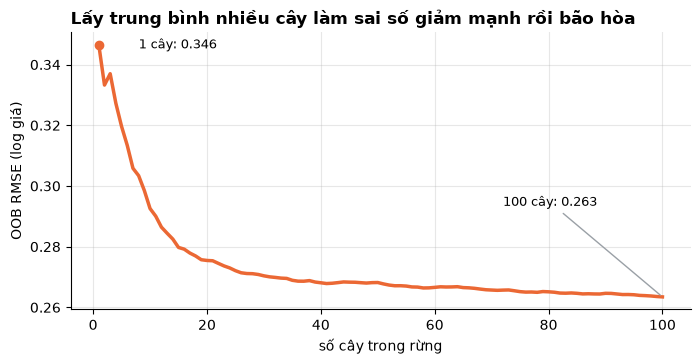

,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ,Thời gian fit (s)
Random Forest - tự cài đặt,0.157,0.09,106.029,388.394,0.887,0.546,0.796,0.356,0.116,0.108,0.158,0.304,150.505


In [11]:
N_TREES = 100
t0 = time.time()
rf_s = RandomForestScratch(n_estimators=N_TREES, random_state=RANDOM_STATE, **best_cfg).fit(XT_tr, y_tr)
t_rf_s = time.time() - t0
print(f"Huấn luyện {N_TREES} cây: {t_rf_s:.0f}s | OOB R² (log) = {rf_s.oob_r2_:.4f} | OOB RMSE (log) = {rf_s.oob_rmse_:.4f}")
print(f"(Bản thư viện: OOB R² (log) = {rf_lib.oob_score_:.4f})")

curve = np.array(rf_s.oob_curve_)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(np.arange(1, N_TREES + 1), curve, color=ORANGE, lw=2.5)
ax.scatter([1], [curve[0]], color=ORANGE, zorder=3)
ax.annotate(f"1 cây: {curve[0]:.3f}", (1, curve[0]), xytext=(8, curve[0]), fontsize=9, va="center")
ax.annotate(f"{N_TREES} cây: {curve[-1]:.3f}", (N_TREES, curve[-1]), xytext=(N_TREES * 0.72, curve[-1] + 0.03),
            fontsize=9, arrowprops=dict(arrowstyle="-", color=GRAY))
ax.set_xlabel("số cây trong rừng"); ax.set_ylabel("OOB RMSE (log giá)")
ax.set_title("Lấy trung bình nhiều cây làm sai số giảm mạnh rồi bão hòa", loc="left")
save(fig, "m05_rf_so_cay"); plt.show()

record("Random Forest - tự cài đặt", rf_s.predict(XT_te), t_rf_s)

## 6. Ridge Regression (thư viện): mô hình so sánh

Ridge dự đoán log giá bằng **tổ hợp tuyến tính** của các đặc trưng, $\hat y = w_0 + \sum_j w_j x_j$, và tìm trọng số bằng cách tối thiểu hóa sai số bình phương cộng khoản phạt L2 $\alpha \sum_j w_j^2$. Khoản phạt giữ hệ số ổn định khi có nhiều cột one-hot tương quan (hãng `Toyota` và dòng `Toyota Vios` luôn đi cùng nhau). Mức phạt `alpha` chọn bằng **5-fold CV trên train**.

Vai trò của Ridge trong notebook này: là **mô hình tuyến tính tốt nhất có thể** trên cùng dữ liệu (đã có `age²`, `log(km)` để biểu diễn khấu hao cong). Phần chênh lệch giữa Ridge và Random Forest chính là đóng góp của **quan hệ phi tuyến và tương tác** (ví dụ xe sang mất giá theo tuổi khác xe phổ thông).

In [12]:
alphas = np.logspace(-3, 3, 25)
t0 = time.time()
gs_ridge = GridSearchCV(Ridge(), {"alpha": alphas}, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                        scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_ridge.fit(XL_tr, y_tr)
best_alpha = gs_ridge.best_params_["alpha"]
print(f"alpha tốt nhất: {best_alpha:.4g} | CV RMSE (log) = {-gs_ridge.best_score_:.4f} | {time.time() - t0:.1f}s")

t0 = time.time()
ridge_lib = Ridge(alpha=best_alpha).fit(XL_tr, y_tr)
record("Ridge - thư viện", ridge_lib.predict(XL_te), time.time() - t0)

alpha tốt nhất: 0.5623 | CV RMSE (log) = 0.2879 | 16.1s


,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ,Thời gian fit (s)
Ridge - thư viện,0.185,0.107,119.564,411.409,0.873,0.475,0.75,0.43,0.139,0.126,0.167,0.343,0.039


## 7. Kết quả trên tập test

Đây là lần **duy nhất** tập test được dùng để đánh giá. Mọi mô hình học trên cùng tập train và được đánh giá trên cùng 2.788 tin test.

In [13]:
ORDER = ["Baseline (trung vị)", "Ridge - thư viện", "Random Forest - thư viện", "Random Forest - tự cài đặt"]
res = pd.DataFrame(results).T.loc[ORDER].astype(float)
main_cols = ["MAPE", "MedAPE", "MAE (triệu)", "RMSE (triệu)", "R2 (log)", "±10%", "±20%", "Thời gian fit (s)"]
seg_cols = [f"MAPE {s}" for s in SEG_LABELS]
res[main_cols].round(3)

,MAPE,MedAPE,MAE (triệu),RMSE (triệu),R2 (log),±10%,±20%,Thời gian fit (s)
Baseline (trung vị),0.835,0.400,336.968,723.755,-0.003,0.137,0.256,0.001
Ridge - thư viện,0.185,0.107,119.564,411.409,0.873,0.475,0.750,0.039
Random Forest - thư viện,0.155,0.090,102.137,372.406,0.891,0.539,0.801,12.238
Random Forest - tự cài đặt,0.157,0.090,106.029,388.394,0.887,0.546,0.796,150.505


In [14]:
res[seg_cols].round(3)

,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ
Baseline (trung vị),3.498,0.385,0.307,0.641,0.854
Ridge - thư viện,0.430,0.139,0.126,0.167,0.343
Random Forest - thư viện,0.347,0.117,0.109,0.157,0.270
Random Forest - tự cài đặt,0.356,0.116,0.108,0.158,0.304


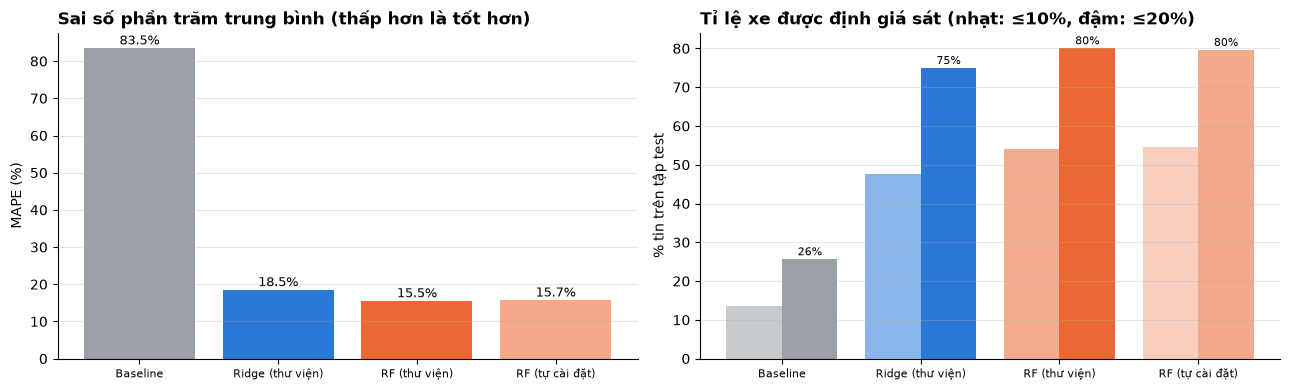

In [15]:
SHOW = ["Ridge - thư viện", "Random Forest - thư viện", "Random Forest - tự cài đặt"]
SHORT = {"Baseline (trung vị)": "Baseline", "Ridge - thư viện": "Ridge (thư viện)",
         "Random Forest - thư viện": "RF (thư viện)", "Random Forest - tự cài đặt": "RF (tự cài đặt)"}
COL = {"Baseline (trung vị)": GRAY, "Ridge - thư viện": BLUE,
       "Random Forest - thư viện": ORANGE, "Random Forest - tự cài đặt": LIGHT_ORANGE}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = ["Baseline (trung vị)"] + SHOW
vals = res.loc[names, "MAPE"] * 100
axes[0].bar([SHORT[n] for n in names], vals, color=[COL[n] for n in names])
for i, v in enumerate(vals):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
axes[0].set_ylabel("MAPE (%)"); axes[0].set_title("Sai số phần trăm trung bình (thấp hơn là tốt hơn)", loc="left")
axes[0].tick_params(axis="x", labelsize=8); axes[0].grid(axis="x", visible=False)

x = np.arange(len(names))
axes[1].bar(x - 0.2, res.loc[names, "±10%"] * 100, 0.4, color=[COL[n] for n in names], alpha=0.55, label="lệch ≤ 10%")
axes[1].bar(x + 0.2, res.loc[names, "±20%"] * 100, 0.4, color=[COL[n] for n in names], label="lệch ≤ 20%")
for i, n in enumerate(names):
    axes[1].text(i + 0.2, res.loc[n, "±20%"] * 100 + 1, f"{res.loc[n, '±20%'] * 100:.0f}%", ha="center", fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels([SHORT[n] for n in names], fontsize=8)
axes[1].set_ylabel("% tin trên tập test"); axes[1].set_title("Tỉ lệ xe được định giá sát (nhạt: ≤10%, đậm: ≤20%)", loc="left")
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "m06_so_sanh_tong"); plt.show()

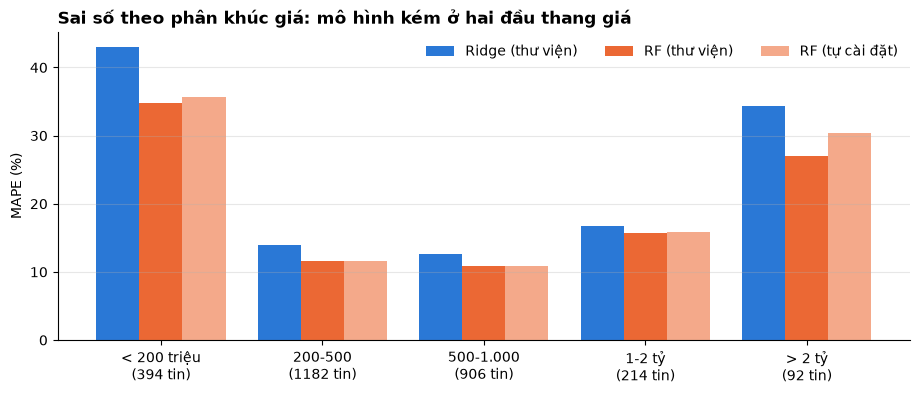

In [16]:
fig, ax = plt.subplots(figsize=(11, 4))
w = 0.8 / len(SHOW)
x = np.arange(len(SEG_LABELS))
for k, n in enumerate(SHOW):
    v = res.loc[n, seg_cols].values * 100
    ax.bar(x + (k - (len(SHOW) - 1) / 2) * w, v, w, color=COL[n], label=SHORT[n])
seg_n = pd.Series(seg_te).value_counts().reindex(SEG_LABELS)
ax.set_xticks(x); ax.set_xticklabels([f"{s}\n({seg_n[s]} tin)" for s in SEG_LABELS])
ax.set_ylabel("MAPE (%)"); ax.set_title("Sai số theo phân khúc giá: mô hình kém ở hai đầu thang giá", loc="left")
ax.legend(frameon=False, ncol=len(SHOW)); ax.grid(axis="x", visible=False)
save(fig, "m07_mape_phan_khuc"); plt.show()

### 7.1 Dự đoán so với giá thật
Mỗi điểm là một xe trong tập test. Điểm càng sát đường chéo thì dự đoán càng đúng. Trục dùng thang log để thấy được cả xe 50 triệu và xe 10 tỷ; trên thang log, khoảng cách tới đường chéo chính là **sai số phần trăm**.

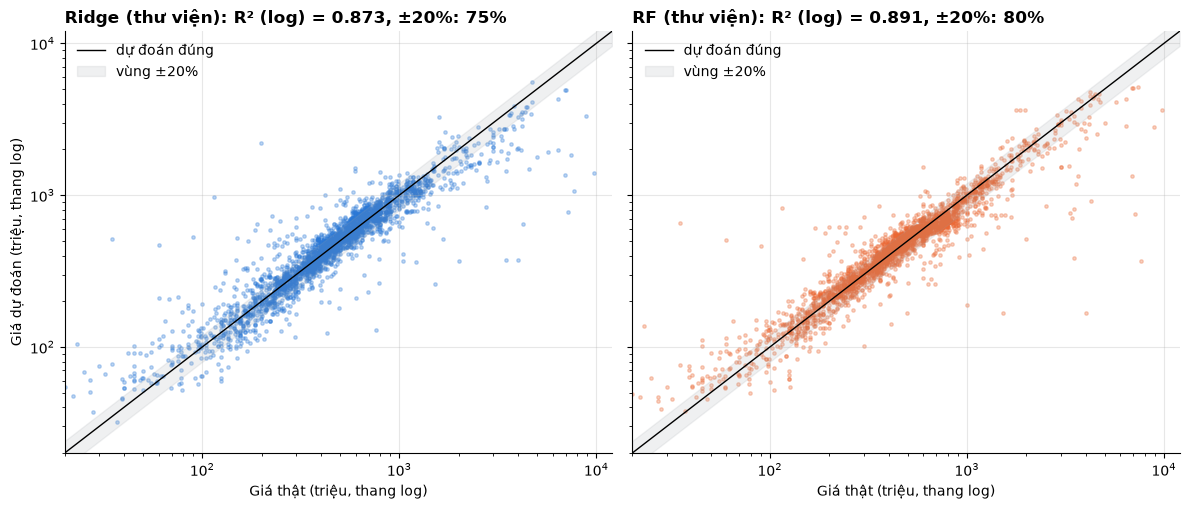

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
lim = [20, 12000]
for ax, n in zip(axes, ["Ridge - thư viện", "Random Forest - thư viện"]):
    ax.scatter(p_te, preds[n], s=6, alpha=0.3, color=COL[n])
    ax.plot(lim, lim, color="black", lw=1, label="dự đoán đúng")
    ax.fill_between(lim, [v * 0.8 for v in lim], [v * 1.2 for v in lim], color=GRAY, alpha=0.15, label="vùng ±20%")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Giá thật (triệu, thang log)")
    ax.set_title(f"{SHORT[n]}: R² (log) = {res.loc[n, 'R2 (log)']:.3f}, ±20%: {res.loc[n, '±20%']:.0%}", loc="left")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Giá dự đoán (triệu, thang log)")
fig.tight_layout(); save(fig, "m08_du_doan_vs_thuc_te"); plt.show()

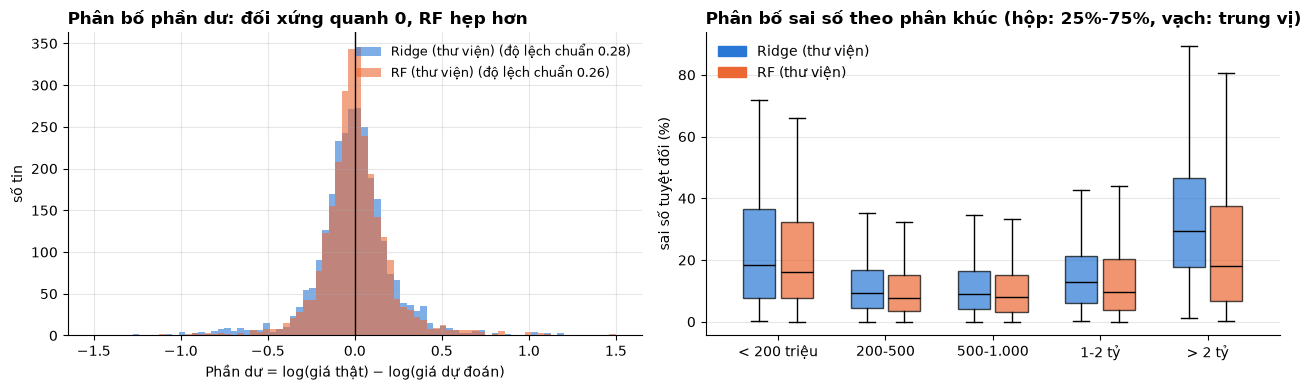

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in ["Ridge - thư viện", "Random Forest - thư viện"]:
    resid = np.log(p_te) - np.log(preds[n])
    axes[0].hist(resid, bins=80, range=(-1.5, 1.5), color=COL[n], alpha=0.6,
                 label=f"{SHORT[n]} (độ lệch chuẩn {resid.std():.2f})")
axes[0].axvline(0, color="black", lw=1)
axes[0].set_xlabel("Phần dư = log(giá thật) − log(giá dự đoán)")
axes[0].set_ylabel("số tin"); axes[0].set_title("Phân bố phần dư: đối xứng quanh 0, RF hẹp hơn", loc="left")
axes[0].legend(frameon=False, fontsize=9)

ape = {n: np.abs(preds[n] - p_te) / p_te * 100 for n in ["Ridge - thư viện", "Random Forest - thư viện"]}
pos = np.arange(len(SEG_LABELS))
for k, n in enumerate(ape):
    data = [ape[n][seg_te == s] for s in SEG_LABELS]
    bp = axes[1].boxplot(data, positions=pos + (k - 0.5) * 0.35, widths=0.3, showfliers=False, patch_artist=True,
                         medianprops=dict(color="black"))
    for b in bp["boxes"]:
        b.set_facecolor(COL[n]); b.set_alpha(0.7)
axes[1].set_xticks(pos); axes[1].set_xticklabels(SEG_LABELS)
axes[1].set_ylabel("sai số tuyệt đối (%)")
axes[1].set_title("Phân bố sai số theo phân khúc (hộp: 25%-75%, vạch: trung vị)", loc="left")
axes[1].legend([plt.Rectangle((0, 0), 1, 1, color=COL[n]) for n in ape], [SHORT[n] for n in ape], frameon=False)
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "m09_phan_du"); plt.show()

### 7.2 Chênh lệch giữa các mô hình có ý nghĩa không? (bootstrap)
Tập test hữu hạn nên MAPE chỉ là một ước lượng: đổi sang một tập test khác thì con số sẽ khác đi một chút. **Bootstrap** ước lượng mức dao động đó: lấy mẫu lại tập test có hoàn lại 1.000 lần, mỗi lần tính lại MAPE, rồi lấy khoảng chứa 95% giá trị ở giữa làm **khoảng tin cậy 95%**.

Để so sánh **hai** mô hình, không nên chỉ nhìn hai khoảng tin cậy có chồng nhau không (cách này quá khắt khe). Cách đúng là **bootstrap ghép cặp**: trong mỗi lần lấy mẫu, tính **hiệu MAPE của hai mô hình trên cùng các xe**. Nếu khoảng tin cậy 95% của hiệu không chứa 0 thì chênh lệch có ý nghĩa thống kê.

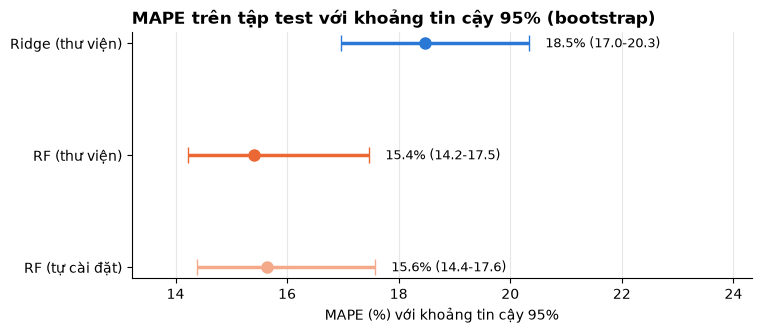

Hiệu MAPE (điểm %), bootstrap ghép cặp:


,2.5%,trung vị,97.5%,có ý nghĩa?
Ridge − Random Forest (thư viện),2.08,2.97,3.97,có
RF tự cài đặt − RF thư viện,-0.04,0.19,0.46,không (khoảng chứa 0)


In [19]:
N_BOOT = 1000
boot_idx = np.random.RandomState(RANDOM_STATE).randint(0, len(p_te), (N_BOOT, len(p_te)))   # cùng các mẫu cho mọi mô hình
ape_te = {n: np.abs(np.clip(preds[n], 1, None) - p_te) / p_te for n in SHOW}
boot = {n: ape_te[n][boot_idx].mean(axis=1) for n in SHOW}                                  # MAPE của từng lần lấy mẫu
ci = pd.DataFrame({n: np.percentile(b, [2.5, 50, 97.5]) for n, b in boot.items()}, index=["2.5%", "trung vị", "97.5%"]).T

# Bootstrap ghép cặp: hiệu MAPE trên cùng các xe
pairs = {"Ridge − Random Forest (thư viện)": ("Ridge - thư viện", "Random Forest - thư viện"),
         "RF tự cài đặt − RF thư viện": ("Random Forest - tự cài đặt", "Random Forest - thư viện")}
diff = pd.DataFrame({k: np.percentile(boot[a] - boot[b], [2.5, 50, 97.5]) * 100 for k, (a, b) in pairs.items()},
                    index=["2.5%", "trung vị", "97.5%"]).T
diff["có ý nghĩa?"] = np.where((diff["2.5%"] > 0) | (diff["97.5%"] < 0), "có", "không (khoảng chứa 0)")

fig, ax = plt.subplots(figsize=(8, 3.2))
for i, n in enumerate(SHOW[::-1]):
    lo, mid, hi = ci.loc[n] * 100
    ax.errorbar(mid, i, xerr=[[mid - lo], [hi - mid]], fmt="o", color=COL[n], capsize=6, lw=2.5, ms=8)
    ax.text(hi + 0.3, i, f"{mid:.1f}% ({lo:.1f}-{hi:.1f})", va="center", fontsize=9)
ax.set_yticks(range(len(SHOW))); ax.set_yticklabels([SHORT[n] for n in SHOW[::-1]])
ax.set_xlabel("MAPE (%) với khoảng tin cậy 95%")
ax.set_title("MAPE trên tập test với khoảng tin cậy 95% (bootstrap)", loc="left")
ax.set_xlim(ci.values.min() * 100 - 1, ci.values.max() * 100 + 4); ax.grid(axis="y", visible=False)
save(fig, "m10_khoang_tin_cay"); plt.show()
print("Hiệu MAPE (điểm %), bootstrap ghép cặp:")
diff.round(2)

**Đọc kết quả:**
- **Random Forest tốt hơn Ridge có ý nghĩa thống kê:** hiệu MAPE khoảng 3,0 điểm %, khoảng tin cậy 95% từ 2,1 đến 4,0, nằm hoàn toàn trên 0.
- **Rừng tự cài đặt và rừng thư viện không khác nhau có ý nghĩa:** hiệu khoảng 0,2 điểm %, khoảng tin cậy từ -0,04 đến 0,46, chứa 0.

### 7.3 Rừng tự cài đặt so với rừng thư viện trên từng xe
Nếu hai bản cài đặt cùng một thuật toán, dự đoán của chúng phải gần như trùng nhau trên từng xe, không chỉ trùng ở con số trung bình.

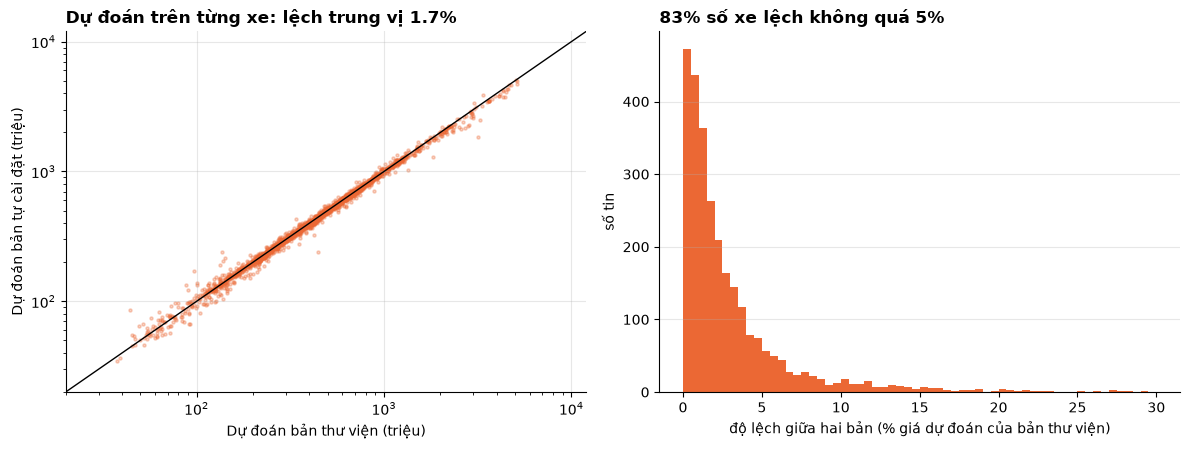

In [20]:
lib, own = "Random Forest - thư viện", "Random Forest - tự cài đặt"
rel_gap = np.abs(preds[own] - preds[lib]) / preds[lib]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(preds[lib], preds[own], s=5, alpha=0.3, color=ORANGE)
axes[0].plot(lim, lim, color="black", lw=1)
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Dự đoán bản thư viện (triệu)"); axes[0].set_ylabel("Dự đoán bản tự cài đặt (triệu)")
axes[0].set_title(f"Dự đoán trên từng xe: lệch trung vị {np.median(rel_gap):.1%}", loc="left")
axes[1].hist(rel_gap * 100, bins=60, range=(0, 30), color=ORANGE)
axes[1].set_xlabel("độ lệch giữa hai bản (% giá dự đoán của bản thư viện)"); axes[1].set_ylabel("số tin")
axes[1].set_title(f"{np.mean(rel_gap <= 0.05):.0%} số xe lệch không quá 5%", loc="left")
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "m11_tu_cai_dat_vs_thu_vien"); plt.show()

## 8. Diễn giải Random Forest: đặc trưng nào quyết định giá?

### 8.1 Độ quan trọng theo mức giảm sai số (impurity)
Một đặc trưng phân loại bị one-hot thành nhiều cột (ví dụ hãng thành 28 cột). Để đọc đúng, **cộng độ quan trọng của mọi cột thuộc cùng một đặc trưng gốc**.

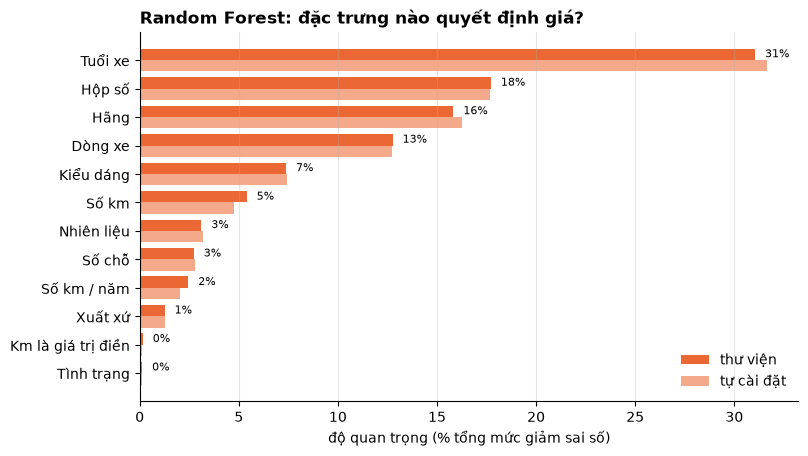

,thư viện,tự cài đặt
Tuổi xe,31.0,31.7
Hộp số,17.7,17.7
Hãng,15.8,16.3
Dòng xe,12.8,12.7
Kiểu dáng,7.4,7.4
Số km,5.4,4.7
Nhiên liệu,3.1,3.2
Số chỗ,2.7,2.8
Số km / năm,2.5,2.0
Xuất xứ,1.3,1.3


In [21]:
FEAT_VI = {"age": "Tuổi xe", "mileage_km": "Số km", "km_per_year": "Số km / năm", "carseats": "Số chỗ",
           "mileage_missing": "Km là giá trị điền", "carbrand_grp": "Hãng", "carmodel_grp": "Dòng xe",
           "carorigin": "Xuất xứ", "condition_ad": "Tình trạng", "gearbox": "Hộp số", "fuel": "Nhiên liệu",
           "cartype": "Kiểu dáng"}


def group_importance(imp, names):
    # Gộp độ quan trọng của các cột one-hot về đặc trưng gốc
    def origin(n):
        return next((c for c in CAT if n.startswith(c + "_")), n)
    return pd.Series(imp, index=[origin(n) for n in names]).groupby(level=0).sum().rename(FEAT_VI)


imp = pd.DataFrame({"thư viện": group_importance(rf_lib.feature_importances_, names_tree),
                    "tự cài đặt": group_importance(rf_s.feature_importances_, names_tree)}).sort_values("thư viện")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
yy = np.arange(len(imp))
ax.barh(yy + 0.2, imp["thư viện"] * 100, 0.4, color=ORANGE, label="thư viện")
ax.barh(yy - 0.2, imp["tự cài đặt"] * 100, 0.4, color=LIGHT_ORANGE, label="tự cài đặt")
for i, v in enumerate(imp["thư viện"] * 100):
    ax.text(v + 0.5, i + 0.2, f"{v:.0f}%", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(imp.index)
ax.set_xlabel("độ quan trọng (% tổng mức giảm sai số)")
ax.set_title("Random Forest: đặc trưng nào quyết định giá?", loc="left")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
save(fig, "m12_do_quan_trong"); plt.show()
(imp.sort_values("thư viện", ascending=False) * 100).round(1)

**Hai bản cài đặt cho cùng thứ hạng** và gần như cùng tỉ lệ, thêm một bằng chứng cho thấy rừng tự viết hoạt động đúng.

### 8.2 Kiểm tra lại bằng permutation importance
Độ quan trọng ở trên (impurity) có hai điểm yếu đã biết:
- **Tính trên train:** đo mức đặc trưng được dùng để chia khi học, kể cả những phép chia chỉ học thuộc nhiễu.
- **Bị lệch khi các đặc trưng tương quan:** ví dụ xe số sàn thường là xe đời cũ, nên **hộp số** và **tuổi xe** mang trùng thông tin. Cây chọn đặc trưng nào để chia ở một nút phần nhiều là ngẫu nhiên, và độ quan trọng bị chia theo cách đó.

**Permutation importance** hỏi trực tiếp: nếu **xáo trộn ngẫu nhiên** một đặc trưng trên tập test (phá vỡ quan hệ của nó với giá, giữ nguyên phân phối), MAPE tăng bao nhiêu? Đo trên **đặc trưng gốc** (xáo trộn cả cột `dòng xe` rồi mới mã hóa), nên không phải cộng các cột one-hot. Lặp 5 lần mỗi đặc trưng và lấy trung bình. Tập test chỉ dùng để **diễn giải** mô hình đã chọn, không dùng để chọn gì.

MAPE gốc trên test: 0.1549 | 13s


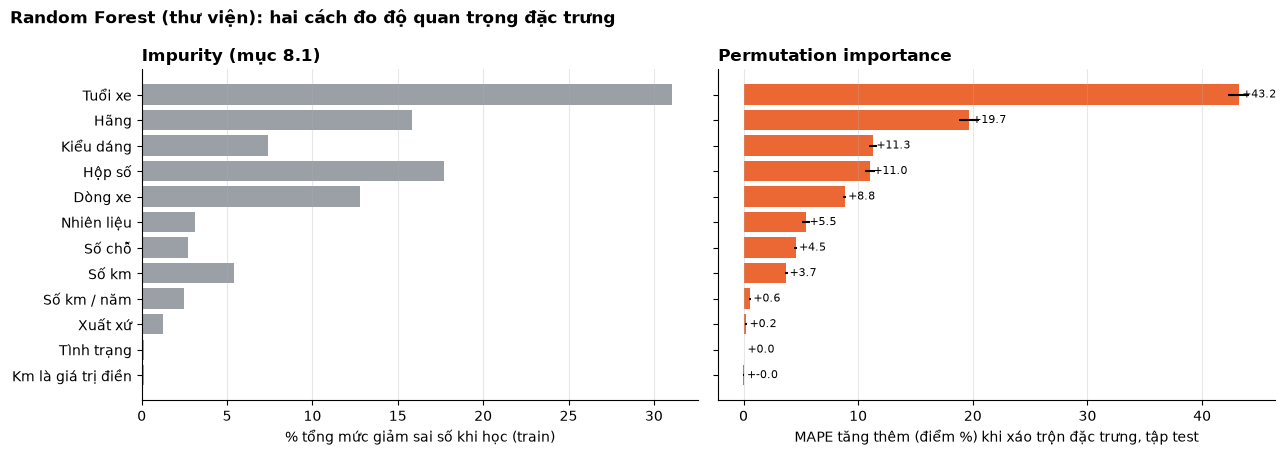

,tăng MAPE (điểm %),độ lệch chuẩn
Tuổi xe,43.20,0.92
Hãng,19.66,0.85
Kiểu dáng,11.29,0.31
Hộp số,11.04,0.46
Dòng xe,8.83,0.15
Nhiên liệu,5.46,0.35
Số chỗ,4.55,0.15
Số km,3.72,0.13
Số km / năm,0.57,0.11
Xuất xứ,0.23,0.07


In [22]:
def permutation_mape(model, prep, frame, cols, n_repeats=5, seed=RANDOM_STATE):
    # Mức tăng MAPE trên tập test khi xáo trộn một đặc trưng gốc (trước khi mã hóa)
    rng = np.random.RandomState(seed)
    base = regression_metrics(p_te, np.exp(model.predict(prep.transform(frame))))["MAPE"]
    rows = {}
    for c in cols:
        inc = []
        for _ in range(n_repeats):
            f = frame.copy()
            f[c] = rng.permutation(f[c].values)
            inc.append(regression_metrics(p_te, np.exp(model.predict(prep.transform(f))))["MAPE"] - base)
        rows[FEAT_VI[c]] = {"tăng MAPE (điểm %)": np.mean(inc) * 100, "độ lệch chuẩn": np.std(inc) * 100}
    return base, pd.DataFrame(rows).T


t0 = time.time()
base_mape, perm = permutation_mape(rf_lib, prep_tree, te[CAT + NUM_TREE], CAT + NUM_TREE)
print(f"MAPE gốc trên test: {base_mape:.4f} | {time.time() - t0:.0f}s")
perm = perm.sort_values("tăng MAPE (điểm %)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
order = perm.index
axes[0].barh(order, imp.loc[order, "thư viện"] * 100, color=GRAY)
axes[0].set_xlabel("% tổng mức giảm sai số khi học (train)")
axes[0].set_title("Impurity (mục 8.1)", loc="left")
axes[1].barh(order, perm["tăng MAPE (điểm %)"], xerr=perm["độ lệch chuẩn"], color=ORANGE)
for i, v in enumerate(perm["tăng MAPE (điểm %)"]):
    axes[1].text(max(v, 0) + 0.3, i, f"+{v:.1f}", va="center", fontsize=8)
axes[1].set_xlabel("MAPE tăng thêm (điểm %) khi xáo trộn đặc trưng, tập test")
axes[1].set_title("Permutation importance", loc="left")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("Random Forest (thư viện): hai cách đo độ quan trọng đặc trưng", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "m15_permutation_importance"); plt.show()
perm.sort_values("tăng MAPE (điểm %)", ascending=False).round(2)

**Đọc biểu đồ:**
- **Tuổi xe** quan trọng nhất theo cả hai cách: xáo trộn tuổi xe làm MAPE tăng khoảng 43 điểm %.
- **Hộp số** tụt từ hạng 2 (impurity khoảng 18%) xuống hạng 4 (+11 điểm %), sau **hãng** (+20) và **kiểu dáng** (+11,3). Điều này khớp với nghi ngờ: một phần độ quan trọng impurity của hộp số là thông tin **trùng với tuổi xe** (xe số sàn thường là xe đời cũ). Khi xáo trộn hộp số, tuổi xe vẫn giữ phần thông tin chung đó.
- **Hãng** lên hạng 2: mức giá chung của thương hiệu là thông tin mà các đặc trưng khác không thay thế được. **Dòng xe** (+8,8) xếp sau hãng vì một phần thông tin của nó đã có trong hãng, kiểu dáng và số chỗ.
- **Số km/năm, xuất xứ, tình trạng, cờ "km là giá trị điền"** gần như bằng 0: bỏ đi cũng không làm mô hình kém đáng kể. Tình trạng mới/cũ đã nằm trong `tuổi = 0` và `km = 0`.
- Lưu ý: xáo trộn từng đặc trưng độc lập có thể tạo tổ hợp không thực tế (xe 0 tuổi đi 200.000 km), nên con số dùng để **xếp hạng**, không phải tác động nhân quả của đặc trưng lên giá.

### 8.3 Đường khấu hao: giá dự đoán theo tuổi xe
Lấy ba mẫu xe phổ biến ở ba phân khúc, cố định mọi thuộc tính, chỉ thay đổi **tuổi xe** (giả định chạy 15.000 km/năm; tuổi 0 là xe mới, 0 km), rồi xem hai mô hình dự đoán giá thế nào. Đây là cách trực quan để thấy mỗi mô hình "hiểu" về khấu hao ra sao.

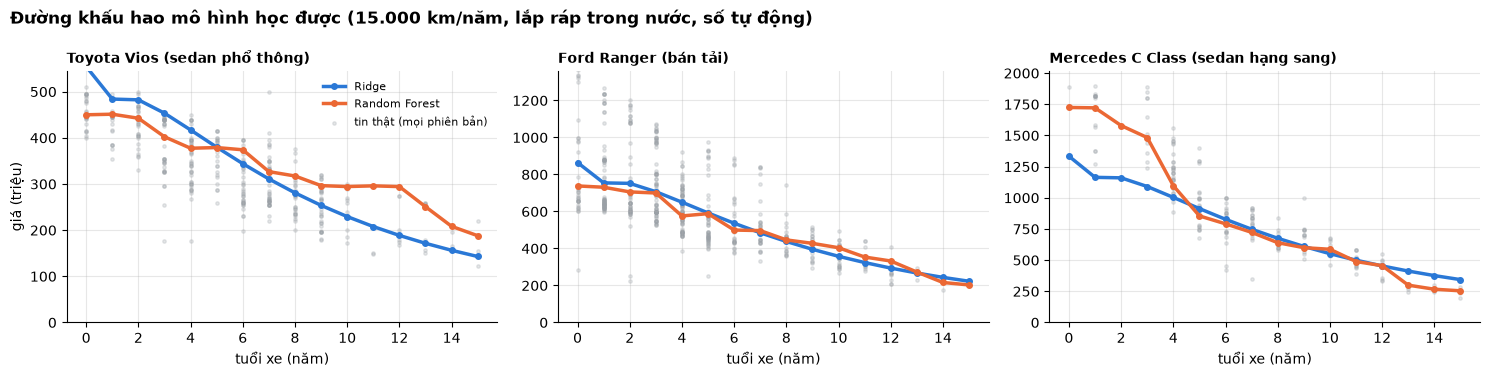

In [23]:
REF_CARS = {
    "Toyota Vios (sedan phổ thông)": dict(carbrand_grp="Toyota", carmodel_grp="Toyota Vios", cartype="Sedan", fuel="Xăng"),
    "Ford Ranger (bán tải)": dict(carbrand_grp="Ford", carmodel_grp="Ford Ranger", cartype="Pick-up (bán tải)", fuel="Dầu"),
    "Mercedes C Class (sedan hạng sang)": dict(carbrand_grp="Mercedes Benz", carmodel_grp="Mercedes Benz C Class",
                                               cartype="Sedan", fuel="Xăng"),
}
ages = np.arange(0, 16)


def depreciation_frame(spec):
    rows = []
    for a in ages:
        km = 15000.0 * a
        rows.append({**spec, "carorigin": "Việt Nam", "gearbox": "Tự động", "carseats": 5,
                     "condition_ad": "Mới" if a == 0 else "Đã sử dụng", "age": a, "age_sq": a * a,
                     "mileage_km": km, "km_per_year": km / max(a, 1), "mileage_missing": 0,
                     "log_km": np.log1p(km), "log_km_per_year": np.log1p(km / max(a, 1))})
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (title, spec) in zip(axes, REF_CARS.items()):
    f = depreciation_frame(spec)
    ax.plot(ages, np.exp(ridge_lib.predict(prep_lin.transform(f))), color=BLUE, lw=2.5, marker="o", ms=4, label="Ridge")
    ax.plot(ages, np.exp(rf_lib.predict(prep_tree.transform(f))), color=ORANGE, lw=2.5, marker="o", ms=4, label="Random Forest")
    real = df[(df["carmodel_grp"] == spec["carmodel_grp"]) & (df["age"] <= 15)]
    ax.scatter(real["age"], real["price_tr"], s=6, color=GRAY, alpha=0.25, label="tin thật (mọi phiên bản)")
    ax.set_title(title, loc="left", fontsize=10); ax.set_xlabel("tuổi xe (năm)")
    ax.set_ylim(0, real["price_tr"].quantile(0.98) * 1.1)
axes[0].set_ylabel("giá (triệu)"); axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Đường khấu hao mô hình học được (15.000 km/năm, lắp ráp trong nước, số tự động)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout(); save(fig, "m13_duong_khau_hao"); plt.show()

**Đọc biểu đồ:**
- **Ridge** cho đường khấu hao **trơn và cùng một hình dạng** cho mọi mẫu xe (chỉ dịch lên xuống theo mức giá của dòng xe), vì mô hình tuyến tính trên log giá giả định mọi xe mất giá **cùng một tỉ lệ %** mỗi năm.
- **Random Forest** cho đường dạng **bậc thang** (cây chia tuổi xe theo ngưỡng) và **hình dạng khác nhau giữa các dòng xe**: mô hình học được rằng mỗi phân khúc khấu hao theo cách riêng. Đây chính là **tương tác** giữa dòng xe và tuổi xe mà Ridge không biểu diễn được, và là lý do Random Forest chính xác hơn.
- Các điểm xám là tin thật của cùng dòng xe ở mọi phiên bản, mọi số km. Độ phân tán dọc lớn cho thấy phần giá mà dữ liệu không giải thích được (phiên bản, trang bị, tình trạng thực tế).

## 9. Thí nghiệm: log giá và các kỹ thuật xử lý mất cân bằng

Hai câu hỏi trả lời bằng số liệu, **trên chính mô hình cuối (Random Forest)**:
1. Học trên **log(giá)** có tốt hơn học trên giá gốc không?
2. Các kỹ thuật **xử lý mất cân bằng** có giúp phân khúc hiếm (xe trên 2 tỷ chỉ khoảng 3%) không?

**Mất cân bằng trong bài toán hồi quy** không có "lớp thiểu số" như phân loại, mà thể hiện ở **mật độ dữ liệu không đều theo vùng giá**: rất nhiều xe 200-1.000 triệu, rất ít xe trên 2 tỷ. Mô hình tối ưu sai số trung bình sẽ học tốt vùng đông và kém ở vùng thưa.

| Kỹ thuật | Cách làm (chỉ trong phần train của mỗi fold) |
|---|---|
| Không cân bằng | huấn luyện bình thường |
| **Trọng số mẫu** | mẫu ở phân khúc hiếm có trọng số lớn hơn: 1/√(tần suất phân khúc), chuẩn hóa về trung bình 1 |
| **Random Oversampling** | nhân bản ngẫu nhiên mẫu của phân khúc hiếm cho đến tối thiểu 25% quy mô phân khúc lớn nhất |
| **Random Undersampling** | bỏ bớt mẫu ở phân khúc đông, mỗi phân khúc giữ tối đa 8 lần số mẫu của phân khúc hiếm nhất |

**Cách đánh giá:** 5-fold CV phân tầng theo phân khúc giá **chỉ trên tập train**. Việc cân bằng chỉ áp dụng cho phần train của từng fold; phần validation **giữ nguyên phân phối thật**. Cân bằng trước khi chia sẽ làm bản sao của cùng một xe nằm ở cả hai phía và cho điểm cao giả tạo. **Tập test không được dùng ở mục này.**

**Vì sao dùng CV chứ không dùng OOB ở mục này:** với oversampling, bản sao của một xe có thể nằm trong bootstrap của một cây trong khi bản gốc là mẫu ngoài túi của chính cây đó, nên OOB đánh giá trên xe mà mô hình đã thấy và cho điểm đẹp giả tạo. CV tách validation **trước** khi nhân bản nên không gặp vấn đề này.

In [24]:
def resample(tr_i, method, rng):
    # Vị trí các mẫu dùng để fit trong phần train của một fold (có thể lặp lại khi oversampling)
    s = seg_tr[tr_i]
    counts = pd.Series(s).value_counts()
    if method == "over":
        target = int(counts.max() * 0.25)
        extra = [rng.choice(tr_i[s == k], target - c, replace=True) for k, c in counts.items() if c < target]
        return np.concatenate([tr_i] + extra)
    if method == "under":
        cap = int(counts.min() * 8)
        return np.concatenate([rng.choice(tr_i[s == k], min(cap, c), replace=False) for k, c in counts.items()])
    return tr_i


def cv_oof(log_target=True, method=None):
    # Dự đoán out-of-fold (triệu đồng) trên tập train bằng Random Forest với tham số tốt nhất
    oof, sizes = np.zeros(len(y_tr)), []
    rng = np.random.RandomState(RANDOM_STATE)
    for tr_i, va_i in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(XT_tr, seg_tr):
        fit_i, w = resample(tr_i, method, rng), None
        if method == "weight":
            s = pd.Series(seg_tr[fit_i])
            w = (1 / np.sqrt(s.map(s.value_counts(normalize=True)))).values
            w = w / w.mean()
        m = RandomForestRegressor(**rs_rf.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
        m.fit(XT_tr[fit_i], (y_tr if log_target else p_tr)[fit_i], sample_weight=w)
        pred = m.predict(XT_tr[va_i])
        oof[va_i] = np.exp(pred) if log_target else pred
        sizes.append(len(fit_i))
    return oof, int(np.mean(sizes))


variants = {"Giá gốc": (False, None), "Log giá": (True, None), "Log giá + trọng số mẫu": (True, "weight"),
            "Log giá + Oversampling": (True, "over"), "Log giá + Undersampling": (True, "under")}
exp_rows = {}
t0 = time.time()
for name, (log_target, method) in variants.items():
    oof, n_fit = cv_oof(log_target, method)
    met = regression_metrics(p_tr, oof)
    exp_rows[name] = {"cỡ train mỗi fold": n_fit, "MAPE": met["MAPE"], "MedAPE": met["MedAPE"],
                      "MAE (triệu)": met["MAE (triệu)"], **segment_mape(p_tr, oof, seg_tr)}
    print(f"{name:28s} MAPE (CV) = {met['MAPE']:.3f}  ({time.time() - t0:.0f}s)")
exp_res = pd.DataFrame(exp_rows).T
exp_res.round(3)

Giá gốc                      MAPE (CV) = 0.196  (54s)


Log giá                      MAPE (CV) = 0.162  (92s)


Log giá + trọng số mẫu       MAPE (CV) = 0.163  (142s)


Log giá + Oversampling       MAPE (CV) = 0.161  (197s)


Log giá + Undersampling      MAPE (CV) = 0.168  (231s)


,cỡ train mỗi fold,MAPE,MedAPE,MAE (triệu),MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ
Giá gốc,8919.0,0.196,0.097,100.019,0.513,0.158,0.115,0.156,0.225
Log giá,8919.0,0.162,0.091,100.146,0.357,0.128,0.108,0.165,0.274
Log giá + trọng số mẫu,8919.0,0.163,0.088,96.398,0.349,0.136,0.112,0.153,0.241
Log giá + Oversampling,9830.0,0.161,0.087,96.357,0.360,0.128,0.110,0.163,0.245
Log giá + Undersampling,6925.0,0.168,0.095,101.446,0.355,0.143,0.110,0.160,0.267


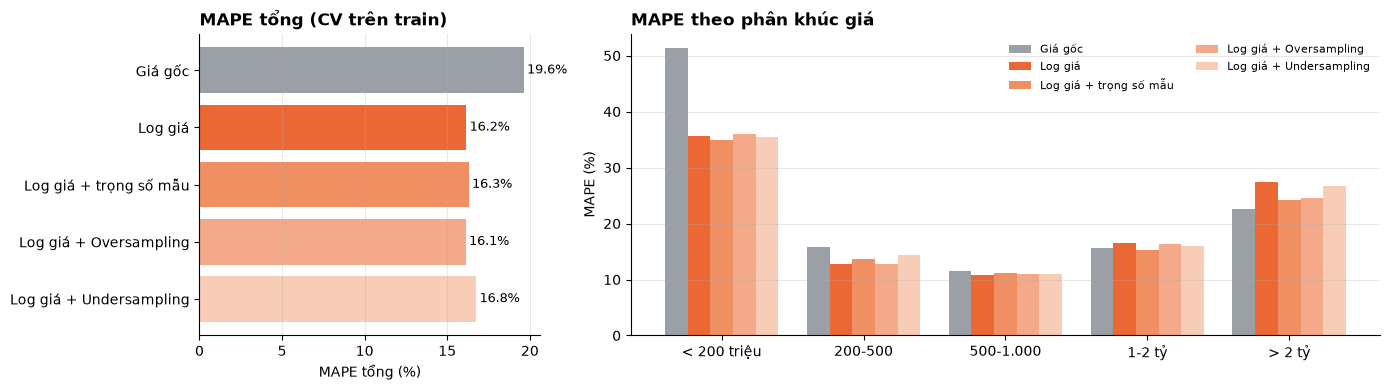

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 2.2]})
exp_colors = [GRAY, ORANGE, "#f08f62", LIGHT_ORANGE, "#f8cdb8"]
v = exp_res["MAPE"] * 100
axes[0].barh(exp_res.index[::-1], v[::-1], color=exp_colors[::-1])
for i, val in enumerate(v[::-1]):
    axes[0].text(val + 0.2, i, f"{val:.1f}%", va="center", fontsize=9)
axes[0].set_xlabel("MAPE tổng (%)"); axes[0].set_title("MAPE tổng (CV trên train)", loc="left")
axes[0].grid(axis="y", visible=False)

w = 0.8 / len(exp_res)
for k, (name, col) in enumerate(zip(exp_res.index, exp_colors)):
    axes[1].bar(np.arange(len(SEG_LABELS)) + (k - 2) * w, exp_res.loc[name, seg_cols].astype(float) * 100, w,
                color=col, label=name)
axes[1].set_xticks(np.arange(len(SEG_LABELS))); axes[1].set_xticklabels(SEG_LABELS)
axes[1].set_ylabel("MAPE (%)"); axes[1].set_title("MAPE theo phân khúc giá", loc="left")
axes[1].legend(frameon=False, fontsize=8, ncol=2); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "m14_log_va_mat_can_bang"); plt.show()

### 9.1 Kết luận thí nghiệm
**1. Log giá tốt hơn rõ rệt.** MAPE tổng giảm từ 19,6% (giá gốc) xuống 16,2% (log giá); phân khúc dưới 200 triệu cải thiện mạnh nhất (51,3% → 35,7%). Học trên giá gốc thì sai số bình phương bị xe đắt chi phối, nên mô hình bỏ qua sai số tương đối ở xe rẻ. Đổi lại, giá gốc tốt hơn ở xe trên 2 tỷ (22,5% so với 27,4%), cũng vì lý do đó. Với thước đo chính là MAPE, **chọn log giá**.

**2. Các kỹ thuật cân bằng không thay đổi MAPE tổng, nhưng giúp phân khúc hiếm:**
- **MAPE tổng** của ba kỹ thuật nằm trong khoảng 16,1-16,8%, so với 16,2% khi không cân bằng.
- **Trọng số mẫu** và **oversampling** giảm sai số ở **xe trên 2 tỷ** khoảng 3 điểm % (27,4% → 24,1% và 24,5%) vì mô hình "nhìn thấy" xe sang nhiều hơn khi học. Trọng số mẫu đổi lại bằng sai số cao hơn ở phân khúc đông nhất 200-500 triệu (12,8% → 13,6%); oversampling gần như không làm phân khúc nào kém đi.
- **Undersampling** bỏ khoảng 22% dữ liệu train (6.925 so với 8.919 mẫu mỗi fold), MAPE tổng tăng lên 16,8% và gần như không giúp xe sang: bỏ dữ liệu thật thì mất thông tin.
- **Giới hạn của cân bằng dữ liệu:** dù đã cân bằng, sai số ở xe trên 2 tỷ vẫn cao gấp đôi phân khúc giữa. Nguyên nhân chủ yếu là **thiếu thông tin** (phiên bản, trang bị quyết định giá xe sang), chứ không chỉ do ít mẫu. Nhân bản dữ liệu không tạo thêm thông tin mới.

**Quyết định:** mô hình cuối **học trên log giá, không dùng kỹ thuật cân bằng**, vì thước đo chính (MAPE trên toàn thị trường) không đổi và mô hình đơn giản hơn. **Nếu ứng dụng ưu tiên định giá xe sang, nên dùng Random Oversampling** (chỉ trên tập train).

## 10. Hạn chế: tin đăng lại và chia theo nhóm

`preprocess_data.ipynb` đã xóa các tin **trùng hoàn toàn** (cùng mọi thuộc tính và cùng giá). Tuy nhiên cùng một chiếc xe có thể được **đăng lại với giá chênh nhẹ**, nên vẫn còn ở dạng hai dòng gần giống nhau. Khi chia ngẫu nhiên, một bản rơi vào train và bản kia vào test; Random Forest với lá nhỏ chỉ cần "nhớ" giá là đoán đúng.

### 10.1 Trên tập test: dòng nào có bản sao trong train?
Bản sao = dòng train **giống hệt mọi đặc trưng, kể cả số km** (cột `group_key` tạo ở mục 1). Với xe đã dùng, trùng cả số km gần như chắc chắn là cùng một xe. Với xe mới (0 km), đó có thể là nhiều xe cùng cấu hình của đại lý.

In [26]:
twin = te["group_key"].isin(set(tr["group_key"])).values
used_te = (te["condition_ad"] == "Đã sử dụng").values

groups = {"có bản sao trong train": twin, "  trong đó xe đã dùng": twin & used_te,
          "không có bản sao": ~twin, "toàn bộ test": np.ones(len(twin), bool)}
rows = {}
for g, msk in groups.items():
    rows[g] = {"số tin": int(msk.sum()), "% test": msk.mean() * 100}
    for n in SHOW:
        rows[g][f"MAPE {SHORT[n]}"] = (np.abs(preds[n] - p_te) / p_te)[msk].mean()
twin_tbl = pd.DataFrame(rows).T
twin_tbl.round(3)

,số tin,% test,MAPE Ridge (thư viện),MAPE RF (thư viện),MAPE RF (tự cài đặt)
có bản sao trong train,391.0,14.024,0.140,0.109,0.108
trong đó xe đã dùng,247.0,8.859,0.140,0.105,0.107
không có bản sao,2397.0,85.976,0.192,0.162,0.165
toàn bộ test,2788.0,100.000,0.185,0.155,0.157


### 10.2 Đánh giá chặt hơn: cross-validation chia theo nhóm
Để có một con số không bị bản sao làm đẹp, chạy lại 5-fold CV trên train cho Random Forest (tham số tốt nhất ở mục 4) theo hai cách:
- **`StratifiedKFold`** (như các mục trên): chia ngẫu nhiên, phân tầng theo phân khúc giá.
- **`StratifiedGroupKFold`**: mọi tin cùng `group_key` luôn nằm **cùng một phía** (cùng train hoặc cùng validation), vẫn giữ phân tầng theo phân khúc giá.

Chênh lệch giữa hai con số là mức **lạc quan** do tin đăng lại. Mục này chỉ dùng tập train.

In [27]:
t0 = time.time()
group_cv = pd.DataFrame({
    "Chia ngẫu nhiên (StratifiedKFold)": cv_rf(lambda: make_prep("tree"), rs_rf.best_params_),
    "Chia theo nhóm (StratifiedGroupKFold)": cv_rf(lambda: make_prep("tree"), rs_rf.best_params_,
                                                   StratifiedGroupKFold(5, shuffle=True, random_state=RANDOM_STATE),
                                                   tr["group_key"].values),
}).T
print(f"{time.time() - t0:.0f}s | số nhóm trong train: {tr['group_key'].nunique()} / {len(tr)} tin")
group_cv.round(4)

112s | số nhóm trong train: 10175 / 11149 tin


,MAPE,MAPE < 200 triệu,MAPE 200-500,MAPE 500-1.000,MAPE 1-2 tỷ,MAPE > 2 tỷ
Chia ngẫu nhiên (StratifiedKFold),0.1614,0.3565,0.1275,0.1084,0.1650,0.2758
Chia theo nhóm (StratifiedGroupKFold),0.1668,0.3804,0.1299,0.1090,0.1694,0.2869


**Nhận xét:**
- Trên tập test, 14% tin có bản sao trong train. Trên nhóm này Random Forest sai 10,9%, trên nhóm không có bản sao sai 16,2%: mô hình "nhớ" được giá của chính chiếc xe đã thấy.
- Chia theo nhóm làm MAPE (CV) của Random Forest tăng từ **16,1% lên 16,7%** (+0,5 điểm %), rõ nhất ở xe dưới 200 triệu (35,7% → 38,0%). Mức lạc quan do tin đăng lại là **có nhưng nhỏ**, và không đổi kết luận nào ở trên.
- **Ước lượng thận trọng** cho một chiếc xe mô hình chưa từng thấy: MAPE khoảng **16-16,5%**, thay vì 15,5% trên toàn bộ tập test.

## 11. Xuất mô hình

Lưu các mô hình đã huấn luyện vào thư mục `model/` (cạnh `src/`) để dùng lại mà không phải huấn luyện lại:

| File | Nội dung |
|---|---|
| `preprocessor_rf.joblib`, `preprocessor_ridge.joblib` | bộ mã hóa của từng mô hình (đã fit trên train) |
| `random_forest_sklearn.joblib`, `ridge_sklearn.joblib` | mô hình thư viện |
| `random_forest_scratch.npz` | các cây và ngưỡng bin của rừng tự cài đặt, lưu dạng mảng NumPy (không phụ thuộc định nghĩa lớp trong notebook) |
| `metadata.json` | danh sách đặc trưng, bảng gộp nhãn hãng/dòng xe, trung vị số km theo năm, tham số tốt nhất, metric trên test |
| `price_model.py` | hàm `load_model` / `predict_price`: nhận thông tin thô của xe, tự dựng đặc trưng như lúc huấn luyện |
| `*.pkl` | (tùy chọn) mỗi mô hình kèm bộ tiền xử lý trong một file, tạo bằng `python export_pkl.py` |

In [28]:
import joblib, sklearn

MODEL_DIR = Path("../model")
MODEL_DIR.mkdir(exist_ok=True)
# File của các phiên bản cũ: bộ tiền xử lý chung, Ridge tự cài đặt (đã bỏ)
for old_file in ["preprocessor.joblib", "ridge_scratch.npz", "ridge_scratch.pkl"]:
    (MODEL_DIR / old_file).unlink(missing_ok=True)

joblib.dump(prep_lin, MODEL_DIR / "preprocessor_ridge.joblib", compress=3)
joblib.dump(prep_tree, MODEL_DIR / "preprocessor_rf.joblib", compress=3)
joblib.dump(ridge_lib, MODEL_DIR / "ridge_sklearn.joblib", compress=3)
joblib.dump(rf_lib, MODEL_DIR / "random_forest_sklearn.joblib", compress=3)

edges = rf_s.binner_.edges_
payload = {"n_trees": len(rf_s.trees_), "edges": np.concatenate(edges),
           "edge_offsets": np.cumsum([0] + [len(e) for e in edges])}
for i, t in enumerate(rf_s.trees_):
    payload.update({f"t{i}_feature": t.feature_, f"t{i}_thr": t.thr_, f"t{i}_left": t.left_,
                    f"t{i}_right": t.right_, f"t{i}_value": t.value_})
np.savez_compressed(MODEL_DIR / "random_forest_scratch.npz", **payload)

used = df["condition_ad"] == "Đã sử dụng"
km_med = df[used & (df["mileage_missing"] == 0)].groupby("mfdate")["mileage_km"].median()
metadata = {
    "target": "ln(giá triệu đồng); dự đoán xong dùng exp() để ra triệu đồng",
    "current_year": 2026,
    "cat_features": CAT, "num_features_ridge": NUM_LIN, "num_features_rf": NUM_TREE,
    # bảng gộp nhãn học từ dữ liệu huấn luyện (giống preprocess_data.ipynb mục 7.2)
    "brand_group": df.groupby("carbrand")["carbrand_grp"].first().to_dict(),
    "model_group": (df.assign(full=df["carbrand"] + " " + df["carmodel"]).groupby("full")["carmodel_grp"].first().to_dict()),
    "luxury_brands": ["Bentley", "Rolls Royce", "Maybach", "Aston Martin", "Ferrari", "Lamborghini", "McLaren",
                      "Maserati", "Cadillac", "Lincoln", "Hummer", "Jaguar", "Infiniti", "Acura", "Volvo",
                      "Alfa Romeo", "MINI", "Jeep", "Genesis", "Lotus"],
    "mileage_median_by_year": {int(k): float(v) for k, v in km_med.items()},
    "mileage_median_all": float(df.loc[used & (df["mileage_missing"] == 0), "mileage_km"].median()),
    "categories": {c: sorted(df[c].unique().tolist()) for c in ["carorigin", "condition_ad", "gearbox", "fuel", "cartype"]},
    "best_params": {"ridge_alpha": float(best_alpha),
                    "random_forest_sklearn": rs_rf.best_params_,
                    "random_forest_scratch": {**best_cfg, "n_estimators": N_TREES}},
    "test_metrics": {k: {m: round(float(v), 4) for m, v in r.items()} for k, r in results.items()},
    "sklearn_version": sklearn.__version__, "n_train": int(len(tr)), "random_state": RANDOM_STATE,
}
with open(MODEL_DIR / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=int)

pd.Series({p.name: p.stat().st_size / 1e6 for p in sorted(MODEL_DIR.iterdir())
           if p.is_file() and p.suffix in {".joblib", ".npz", ".json", ".py"}}).round(2).to_frame("MB")

,MB
export_pkl.py,0.00
metadata.json,0.03
preprocessor_rf.joblib,0.00
preprocessor_ridge.joblib,0.00
price_model.py,0.01
random_forest_scratch.npz,6.24
random_forest_sklearn.joblib,48.85
ridge_sklearn.joblib,0.00


**Kiểm tra:** nạp lại mô hình bằng `price_model.py`, truyền vào **thông tin thô** của các xe trong tập test (hãng, dòng xe gốc, năm sản xuất, số km...), để module tự dựng đặc trưng như lúc huấn luyện. Dự đoán phải trùng khớp với dự đoán trong notebook.

In [29]:
sys.path.insert(0, str(MODEL_DIR))
import importlib, price_model
importlib.reload(price_model)

name_map = {"random_forest_sklearn": "Random Forest - thư viện", "random_forest_scratch": "Random Forest - tự cài đặt",
            "ridge_sklearn": "Ridge - thư viện"}
raw_test = te[["carbrand", "carmodel", "carorigin", "condition_ad", "gearbox", "fuel", "cartype", "carseats",
               "mfdate", "mileage_km", "mileage_missing"]]
for key, label in name_map.items():
    p_loaded = price_model.predict_price(price_model.load_model(key), raw_test)
    print(f"{key:24s} lệch lớn nhất so với notebook = {np.abs(p_loaded - preds[label]).max():.1e} triệu")
    assert np.allclose(p_loaded, preds[label], rtol=1e-9, atol=1e-6)

demo = pd.DataFrame([
    {"carbrand": "Toyota", "carmodel": "Vios", "carorigin": "Việt Nam", "condition_ad": "Đã sử dụng", "gearbox": "Tự động",
     "fuel": "Xăng", "cartype": "Sedan", "carseats": 5, "mfdate": 2018, "mileage_km": 80000},
    {"carbrand": "Ford", "carmodel": "Ranger", "carorigin": "Thái Lan", "condition_ad": "Đã sử dụng", "gearbox": "Tự động",
     "fuel": "Dầu", "cartype": "Pick-up (bán tải)", "carseats": 5, "mfdate": 2021, "mileage_km": None},
])
out = pd.DataFrame({k: price_model.predict_price(price_model.load_model(k), demo) for k in name_map},
                   index=["Toyota Vios 2018, 80.000 km", "Ford Ranger 2021, không rõ km"]).round(0)
out

random_forest_sklearn    lệch lớn nhất so với notebook = 9.1e-12 triệu


random_forest_scratch    lệch lớn nhất so với notebook = 0.0e+00 triệu
ridge_sklearn            lệch lớn nhất so với notebook = 0.0e+00 triệu


,random_forest_sklearn,random_forest_scratch,ridge_sklearn
"Toyota Vios 2018, 80.000 km",303.0,303.0,281.0
"Ford Ranger 2021, không rõ km",515.0,536.0,596.0


## 12. Kết luận

Số liệu lấy từ lần chạy với `random_state = 42` (train 11.149 tin, test 2.788 tin).

### 12.1 Kết quả trên tập test

| Mô hình | MAPE | MedAPE | R² (log) | Lệch ≤ 10% | Lệch ≤ 20% | Thời gian huấn luyện |
|---|---|---|---|---|---|---|
| Baseline (luôn đoán trung vị) | 83,5% | 40,0% | 0,00 | 14% | 26% | - |
| Ridge (thư viện, so sánh) | 18,5% | 10,7% | 0,873 | 48% | 75% | 0,04 giây |
| **Random Forest (thư viện)** | **15,5%** | **9,0%** | **0,891** | 54% | **80%** | 12 giây |
| **Random Forest (tự cài đặt)** | 15,7% | 9,0% | 0,887 | 55% | 80% | 2,5 phút |

| Phân khúc | % dữ liệu | Ridge | RF (thư viện) | RF (tự cài đặt) |
|---|---|---|---|---|
| < 200 triệu | 14% | 43,0% | 34,7% | 35,6% |
| 200-500 triệu | 42% | 13,9% | 11,7% | 11,6% |
| 500-1.000 triệu | 33% | 12,6% | 10,9% | 10,8% |
| 1-2 tỷ | 8% | 16,7% | 15,7% | 15,8% |
| > 2 tỷ | 3% | 34,3% | 27,0% | 30,4% |

1. **Random Forest là mô hình tốt nhất:** 4 trên 5 xe được định giá lệch không quá 20%, sai số điển hình (MedAPE) khoảng 9%. Phân khúc giữa (200 triệu - 1 tỷ, khoảng 75% thị trường) sai khoảng 11%.
2. **Random Forest tốt hơn Ridge khoảng 3 điểm % và có ý nghĩa thống kê** (KTC 95% của hiệu: 2,1-4,0), tốt hơn ở mọi phân khúc. Phần chênh này là đóng góp của **quan hệ phi tuyến và tương tác**: đường khấu hao (mục 8.3) cho thấy mỗi dòng xe mất giá theo cách riêng, điều Ridge không biểu diễn được.
3. **Hai đầu thang giá vẫn khó:** xe dưới 200 triệu (giá thấp nên chênh vài chục triệu đã là phần trăm lớn; tình trạng xe cũ rất khác nhau) và xe trên 2 tỷ (ít mẫu, thiếu thông tin phiên bản, trang bị).

### 12.2 Bản tự cài đặt
- **Một cây:** với cùng tham số, cây tự viết có số nút (3.429 so với 3.481) và R² gần như bằng cây của `sklearn`.
- **Cả rừng:** MAPE 15,7% so với 15,5%, chênh lệch **không có ý nghĩa thống kê**; OOB R² 0,892 so với 0,896; cùng thứ hạng độ quan trọng đặc trưng. Chênh lệch nhỏ đến từ việc chia đặc trưng thành 32 bin, dùng 100 cây thay vì 300, và cấu hình tinh chỉnh bằng OOB hơi khác (`min_samples_leaf = 2`). Rõ nhất ở xe trên 2 tỷ (30,4% so với 27,0%), nơi ít mẫu nên bin thô và lá lớn hơn ảnh hưởng nhiều hơn.
- **Chi phí:** rừng tự viết bằng Python mất khoảng 2,5 phút, bản thư viện 12 giây (C/Cython, chạy song song).

### 12.3 Các quyết định đã kiểm chứng bằng CV/OOB trên train
- **Mã hóa one-hot** tốt hơn mã số thứ tự (MAPE 16,4% so với 16,7-18,4%).
- **Tham số rừng:** `max_depth = 30`, `max_features = 0.5`, `min_samples_leaf = 1` (thư viện, CV); `min_samples_leaf = 2` (tự cài đặt, OOB).
- **Log giá:** MAPE 16,2% so với 19,6% khi học trên giá gốc.
- **Mất cân bằng:** trọng số mẫu và oversampling giữ nguyên MAPE tổng nhưng giảm khoảng 3 điểm % sai số ở xe trên 2 tỷ; undersampling kém hơn. Mô hình cuối không cân bằng; oversampling là lựa chọn nếu ưu tiên xe sang.
- **Yếu tố quyết định giá** (permutation importance trên test): tuổi xe, hãng, kiểu dáng, hộp số, dòng xe. Impurity xếp hộp số thứ 2 một phần vì hộp số trùng thông tin với tuổi xe.

### 12.4 Hạn chế và hướng phát triển
- **Giá rao bán, không phải giá giao dịch:** luôn có phần thương lượng mà mô hình không biết.
- **Tin đăng lại:** chia theo nhóm cho MAPE (CV) 16,7% so với 16,1% khi chia ngẫu nhiên, nên con số 15,5% trên test hơi lạc quan; ước lượng thận trọng khoảng 16-16,5%.
- **Thiếu đặc trưng quan trọng:** phiên bản/trang bị, tình trạng thân vỏ và nội thất, số đời chủ. Crawl thêm phần mô tả tin đăng có thể bổ sung.
- **Giá dự đoán** là `exp()` của dự đoán log giá, tức ước lượng **trung vị** của giá; phù hợp với MAPE nên không hiệu chỉnh.
- **Hướng mở rộng:** Gradient Boosting (học tuần tự các cây sửa lỗi của nhau) có thể dùng lại lớp cây đã tự cài đặt.